# Hat 형상 성형공정 ANN–GA 최적화 — 원본 자료 교차검토판

**과제 원문 기준:** ① ANN 및 하이퍼파라미터 최적화 ② 7개 출력의 R² Parity Plot ③ GA로 최종 제품 목표값 `[L1,L2,θ,θspb,R1,R2,H]=[18,14,40,0,5.5,6,10]`에 가장 가까운 **금형 형상 입력값** 찾기.

자료 기준 순서: 과제 공지 → `MLP_Hat형상예측.pdf` 및 형상정보 PPT → 실제 `input.csv`, `target.csv` → 제공 논문(JKSPE-025-00048). 논문은 참고 연구이며 모든 수치를 그대로 복제하는 조건이 아님.

**주의:** 논문은 900개 사례·4 입력·Z-score·3 은닉층·SCG를 기술하지만, 제공된 CSV는 891행이며 강의실습 조건은 0–1 정규화·5 은닉층·Adam. 현재 구현은 강의조건을 따른다. CSV의 변동 입력 5개 중 독립 금형 설계 자유도는 4개다.

**재실행 조건:** `input.csv`와 `target.csv`를 Google Drive `MyDrive/` 최상위에 업로드. STEP 5~9는 앞 단계에서 생성하는 정규화 파일, 선정 `.keras` 모델, 해시/검증 결과를 같은 `Hat_ANN_GA_results` 폴더에 저장한 상태를 필요로 한다. 신규 Colab/다른 TensorFlow 버전에서 기존 저장결과를 덮어쓰면 모델 선정이나 파일 해시가 달라질 수 있다. 이 문서는 기존 실행 출력의 증거를 보존하며, 새로운 검증 셀은 별도 실행이 필요하다.

## 먼저 확인할 해석상의 함정

- 입력 `R1=5 mm`, `R2=6 mm`는 금형에서 고정이지만 **출력** `R1`, `R2`는 성형 후 변하는 예측값이다. `Model`은 식별자라 학습에서 제외한다.
- `theta1` 입력은 음수, 출력 `Theta1_out`은 양수로 정의된다. `theta2` 입력과 출력 `Theta2_out`은 서로 다른 물리량/단계다.
- 목표 `L2=14 mm`는 **제품 출력** 목표이고 금형 입력의 L2에 그대로 대입하는 값이 아니다.
- Train에서만 scaler를 fit하고, Validation으로 ANN을 선택하며, Test는 선정 후 1회 성능 평가한다. GA가 Test 평가 지표를 적합도 함수로 사용하지 않는다.
- GA 목적함수의 7개 가중치 `[1,1,2,3,4,3,3]`는 연구 논문의 **형식**을 차용한 자체 설정값이다(변수 순서 `[L1,L2,H,Theta1_out,Theta2_out,R1,R2]`).
- `STEP 7: PASS`는 수치/파일/기하학 조건 검사 통과이며 실제 Abaqus 재해석·제품 제작·필렛 CAD 간섭·파단/주름 검증과는 다르다.

In [1]:

# ============================================================
# STEP 1. Google Drive 연결 및 데이터 검증
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Google Drive 연결
drive.mount('/content/drive')

# 2. 파일 경로 설정 (내 드라이브 최상위 폴더)
base_path = Path('/content/drive/MyDrive')
input_path = base_path / 'input.csv'
target_path = base_path / 'target.csv'

# 3. 파일 존재 여부 확인
for path in [input_path, target_path]:
    assert path.is_file(), f"파일을 찾을 수 없습니다: {path}"
    print(f"[OK] 파일 확인: {path.name}")

# 4. CSV 데이터 불러오기
input_df = pd.read_csv(input_path)
target_df = pd.read_csv(target_path)

# 5. 열 이름 및 구조 검증
expected_input = [
    'Model', 'L1', 'L2', 'H',
    'theta1', 'theta2', 'R1', 'R2'
]

expected_target = [
    'Model', 'L1', 'L2', 'H',
    'Theta1_out', 'Theta2_out', 'R1', 'R2'
]

assert input_df.columns.tolist() == expected_input, \
    "입력 CSV의 열 구성이 다릅니다."

assert target_df.columns.tolist() == expected_target, \
    "출력 CSV의 열 구성이 다릅니다."

# 6. 데이터 정합성 검증
assert input_df.shape == (891, 8), "입력 데이터 크기 오류"
assert target_df.shape == (891, 8), "출력 데이터 크기 오류"

assert input_df['Model'].equals(target_df['Model']), \
    "입력과 출력의 Model 번호 또는 순서가 다릅니다."

assert input_df['Model'].is_unique, \
    "중복된 Model 번호가 존재합니다."

assert not input_df.isna().any().any(), \
    "입력 데이터에 결측값이 있습니다."

assert not target_df.isna().any().any(), \
    "출력 데이터에 결측값이 있습니다."

assert all(pd.api.types.is_numeric_dtype(
    input_df[c]) for c in expected_input), \
    "입력 데이터에 숫자가 아닌 열이 있습니다."

assert all(pd.api.types.is_numeric_dtype(
    target_df[c]) for c in expected_target), \
    "출력 데이터에 숫자가 아닌 열이 있습니다."

# 7. 학습용 입력 및 출력 정의
input_cols = ['L1', 'L2', 'H', 'theta1', 'theta2']
target_cols = [
    'L1', 'L2', 'H',
    'Theta1_out', 'Theta2_out', 'R1', 'R2'
]

X = input_df[input_cols].copy()
Y = target_df[target_cols].copy()

# 8. 고정 곡률반경 확인
assert (input_df['R1'] == 5).all(), "입력 R1 값 확인 필요"
assert (input_df['R2'] == 6).all(), "입력 R2 값 확인 필요"

# 9. 결과 출력
print("\n========== 검증 결과 ==========")
print("입력 데이터:", X.shape)
print("출력 데이터:", Y.shape)
print("결측값:", X.isna().sum().sum() + Y.isna().sum().sum())
print("모델 번호 일치: True")
print("입력 곡률반경: R1=5, R2=6")
print("데이터 검증: PASS")

print("\n[입력 데이터 샘플]")
display(X.head())

print("\n[출력 데이터 샘플]")
display(Y.head())

print("\n[입력 변수 통계]")
display(X.describe().T)

print("\n[출력 변수 통계]")
display(Y.describe().T)



Mounted at /content/drive
[OK] 파일 확인: input.csv
[OK] 파일 확인: target.csv

========== 검증 결과 ==========
입력 데이터: (891, 5)
출력 데이터: (891, 7)
결측값: 0
모델 번호 일치: True
입력 곡률반경: R1=5, R2=6
데이터 검증: PASS

[입력 데이터 샘플]


,L1,L2,H,theta1,theta2
0,12,25,10,-37.568592,13.495733
1,12,25,10,-37.568592,6.842773
2,12,25,10,-37.568592,2.290610
3,12,25,11,-37.568592,-2.290610
4,12,25,13,-37.568592,-6.842773



[출력 데이터 샘플]


,L1,L2,H,Theta1_out,Theta2_out,R1,R2
0,12.8934,19.9829,9.702378,38.165529,13.147413,5.672830,5.211105
1,12.8936,20.3738,9.923327,38.100346,6.503050,5.673869,5.587109
2,12.8924,20.4887,10.110393,38.145484,1.904953,5.681345,5.948304
3,12.8914,20.4753,11.203789,38.189435,-2.625460,5.677835,6.645034
4,13.3156,20.8147,12.973187,38.193011,-7.319749,7.408743,5.454433



[입력 변수 통계]


,count,mean,std,min,25%,50%,75%,max
L1,891.0,16.774411,3.704485,12.000000,14.000000,16.000000,20.000000,22.000000
L2,891.0,20.991021,2.823642,17.000000,19.000000,21.000000,23.000000,25.000000
H,891.0,16.668911,4.056252,10.000000,14.000000,17.000000,20.000000,26.000000
theta1,891.0,-51.575083,12.592184,-81.469234,-60.642246,-50.906141,-42.709390,-25.463345
theta2,891.0,0.065058,10.696553,-19.440035,-8.130102,2.290610,8.130102,19.440035



[출력 변수 통계]


,count,mean,std,min,25%,50%,75%,max
L1,891.0,17.318513,3.184425,12.448900,14.855900,17.038200,20.487900,23.251100
L2,891.0,12.419878,3.313755,4.357200,9.976100,12.371800,14.766050,20.814700
H,891.0,16.352658,3.668858,9.093919,13.484812,16.548300,19.222604,23.947245
Theta1_out,891.0,52.524459,12.602571,25.830153,43.503110,51.462986,61.269688,82.185622
Theta2_out,891.0,-0.926812,10.878080,-21.629050,-9.236249,0.951213,7.393618,19.140801
R1,891.0,5.647888,0.711393,4.943903,5.283347,5.387068,5.632478,9.473459
R2,891.0,5.615202,0.650369,4.938650,5.326532,5.416909,5.574578,9.903629


In [2]:

# ============================================================
# STEP 2. 데이터 분할 및 정규화
# ============================================================

import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# 1. 데이터 재확인
# ------------------------------------------------------------
assert X.shape == (891, 5), "입력 데이터 크기 오류"
assert Y.shape == (891, 7), "출력 데이터 크기 오류"

assert np.isfinite(X.to_numpy()).all(), "입력에 비정상 값"
assert np.isfinite(Y.to_numpy()).all(), "출력에 비정상 값"

# ------------------------------------------------------------
# 2. 데이터 분할 (70 : 15 : 15)
# ------------------------------------------------------------
RANDOM_SEED = 42
indices = np.arange(len(X))

# 전체 데이터 중 15%를 Test로 분리
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=RANDOM_SEED,
    shuffle=True
)

# 나머지 85%에서 Validation 15%p를 분리
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.15 / 0.85,
    random_state=RANDOM_SEED,
    shuffle=True
)

# 원본 데이터 분리
X_train_raw = X.iloc[train_idx].copy()
X_val_raw = X.iloc[val_idx].copy()
X_test_raw = X.iloc[test_idx].copy()

Y_train_raw = Y.iloc[train_idx].copy()
Y_val_raw = Y.iloc[val_idx].copy()
Y_test_raw = Y.iloc[test_idx].copy()

# ------------------------------------------------------------
# 3. 데이터 누출 검증
# ------------------------------------------------------------
assert len(train_idx) == 623
assert len(val_idx) == 134
assert len(test_idx) == 134

assert len(np.unique(np.concatenate([
    train_idx, val_idx, test_idx
]))) == len(X), "분할 중 중복 또는 누락 발생"

# ------------------------------------------------------------
# 4. Min-Max 정규화
#    반드시 Train 데이터로만 학습
# ------------------------------------------------------------
X_scaler = MinMaxScaler(feature_range=(0, 1))
Y_scaler = MinMaxScaler(feature_range=(0, 1))

X_scaler.fit(X_train_raw)
Y_scaler.fit(Y_train_raw)

# Train, Validation, Test에 동일한 기준 적용
X_train = X_scaler.transform(X_train_raw).astype(np.float32)
X_val = X_scaler.transform(X_val_raw).astype(np.float32)
X_test = X_scaler.transform(X_test_raw).astype(np.float32)

Y_train = Y_scaler.transform(Y_train_raw).astype(np.float32)
Y_val = Y_scaler.transform(Y_val_raw).astype(np.float32)
Y_test = Y_scaler.transform(Y_test_raw).astype(np.float32)

# ------------------------------------------------------------
# 5. 역정규화 정상 작동 검증
# ------------------------------------------------------------
Y_test_restored = Y_scaler.inverse_transform(Y_test)

assert np.allclose(
    Y_test_restored,
    Y_test_raw.to_numpy(),
    atol=1e-4,
    rtol=1e-5
), "역정규화 검증 실패"

# ------------------------------------------------------------
# 6. 분할 정보와 정규화 모델 저장
# ------------------------------------------------------------
results_dir = base_path / "Hat_ANN_GA_results"
results_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    results_dir / "split_indices.npz",
    train=train_idx,
    validation=val_idx,
    test=test_idx
)

joblib.dump(X_scaler, results_dir / "X_scaler.joblib")
joblib.dump(Y_scaler, results_dir / "Y_scaler.joblib")

# ------------------------------------------------------------
# 7. 최종 검증 결과 출력
# ------------------------------------------------------------
print("========== STEP 2 검증 결과 ==========")

print("Train :", X_train.shape, Y_train.shape)
print("Val   :", X_val.shape, Y_val.shape)
print("Test  :", X_test.shape, Y_test.shape)

print("\nTrain 입력 범위:",
      X_train.min(), "~", X_train.max())

print("Train 출력 범위:",
      Y_train.min(), "~", Y_train.max())

print("\n데이터 중복/누락: 없음")
print("역정규화 검증: PASS")
print("저장 경로:", results_dir)
print("STEP 2: PASS")


========== STEP 2 검증 결과 ==========
Train : (623, 5) (623, 7)
Val   : (134, 5) (134, 7)
Test  : (134, 5) (134, 7)

Train 입력 범위: 0.0 ~ 1.0
Train 출력 범위: 0.0 ~ 1.0

데이터 중복/누락: 없음
역정규화 검증: PASS
저장 경로: /content/drive/MyDrive/Hat_ANN_GA_results
STEP 2: PASS


========== 기하학 검증 ==========
높이 최대 절대오차: 6.29e-09 mm
Y3 설계 수준: [-20, -18, -16, -14, -12, -10]
Offset 설계 수준: [-6, -3, -1, 1, 3, 6]
기하학 검증: PASS

========== Train 입력 통계 ==========


,L1,L2,H,theta1,theta2
min,12.000,17.000,10.000,-81.469,-19.440
mean,16.799,20.958,16.655,-51.447,-0.330
std,3.650,2.816,4.017,12.697,10.771
max,22.000,25.000,26.000,-25.463,19.440



========== Train 출력 통계 ==========


,L1,L2,H,Theta1_out,Theta2_out,R1,R2
min,12.449,4.445,9.094,25.830,-21.629,4.983,4.939
mean,17.355,12.436,16.334,52.403,-1.311,5.660,5.631
std,3.143,3.221,3.627,12.706,10.954,0.728,0.666
max,23.248,20.815,23.830,82.043,19.059,9.448,9.733



========== 목표값 범위 검사 ==========


,Variable,Train min,Target,Train max,Within range
0,L1,12.449,18.0,23.248,True
1,L2,4.445,14.0,20.815,True
2,H,9.094,10.0,23.830,True
3,Theta1_out,25.830,40.0,82.043,True
4,Theta2_out,-21.629,0.0,19.059,True
5,R1,4.983,5.5,9.448,True
6,R2,4.939,6.0,9.733,True


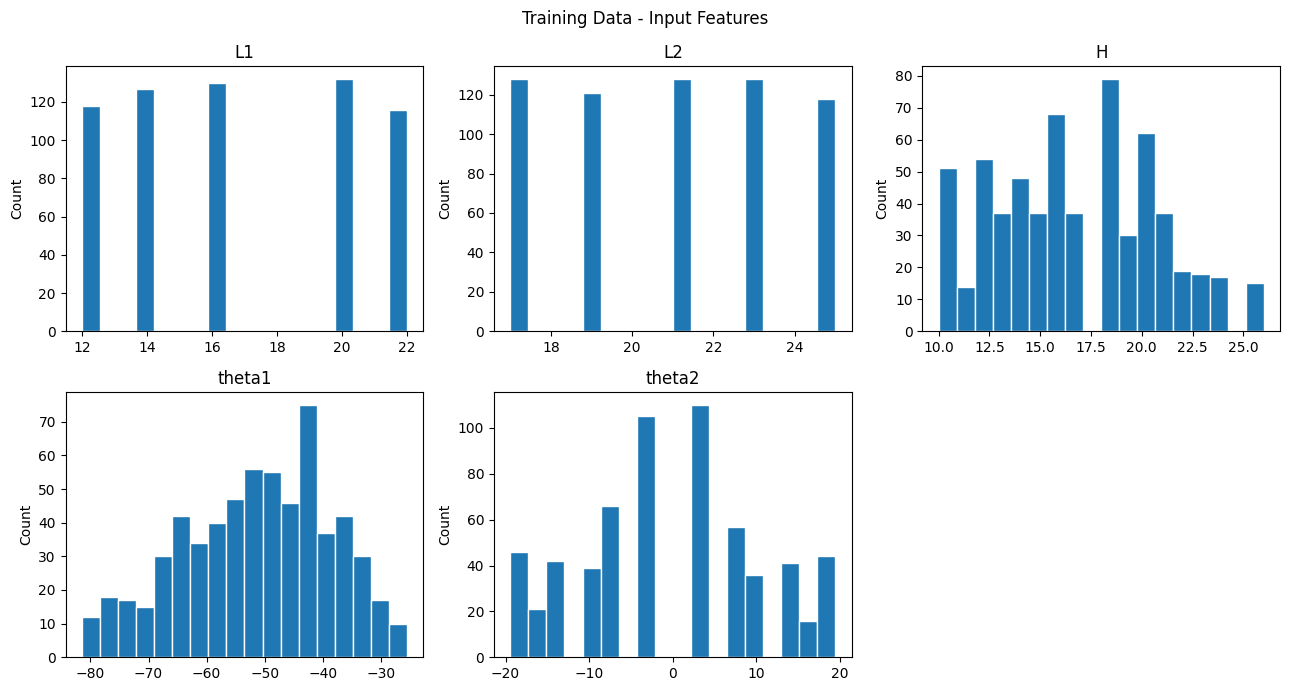

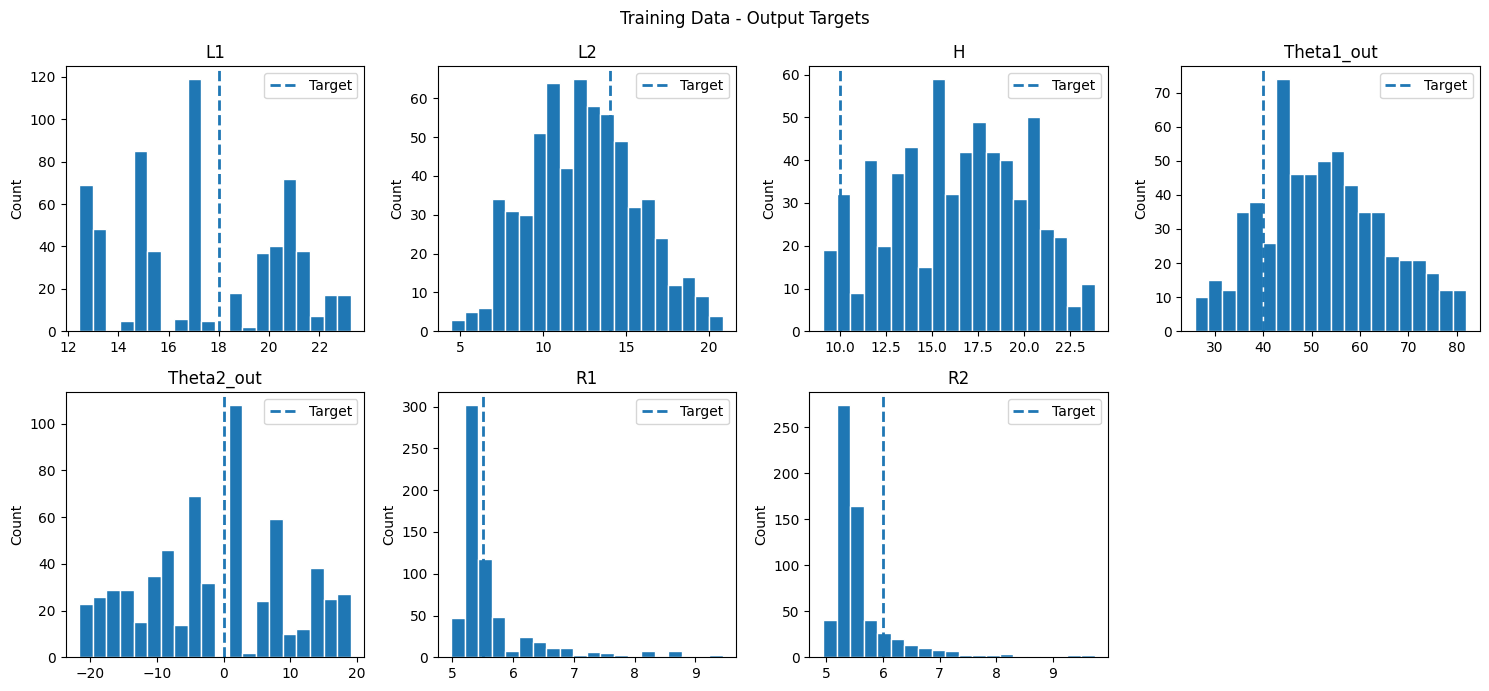

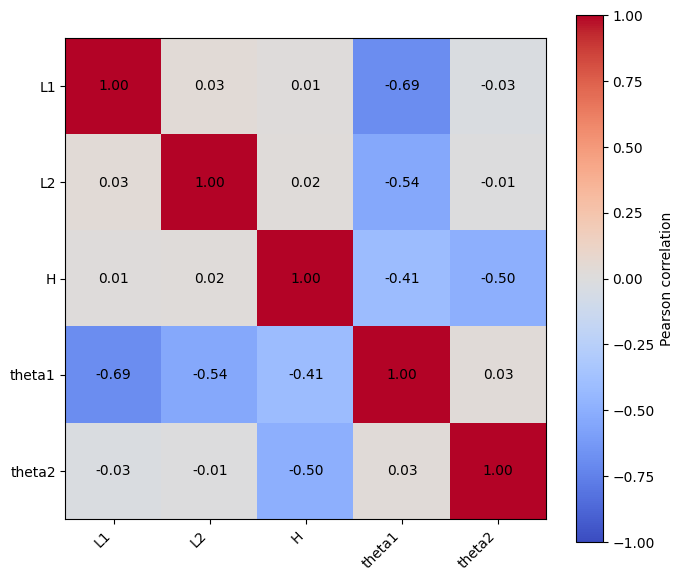


========== STEP 3 결과 ==========
기하학 검증: PASS
목표값 변수별 범위 검사: PASS
그래프 3개 저장 완료
저장 경로: /content/drive/MyDrive/Hat_ANN_GA_results
STEP 3: PASS


In [3]:

# ============================================================
# STEP 3. 데이터 탐색 및 기하학적 관계 검증
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. 금형 기하학적 관계 검증
#    강의자료의 P1, P2, P3, P4 정의 기준
# ------------------------------------------------------------

x2 = input_df['L1'].to_numpy(dtype=float)
x3 = 50.0 - input_df['L2'].to_numpy(dtype=float)

theta1 = np.deg2rad(input_df['theta1'].to_numpy(dtype=float))
theta2 = np.deg2rad(input_df['theta2'].to_numpy(dtype=float))

# 금형 하부 특징점 P3, P4의 Y 좌표 복원
y3 = (x3 - x2) * np.tan(theta1)
offset = input_df['L2'].to_numpy(dtype=float) * np.tan(theta2)
y4 = y3 + offset

# 최상단과 최하단 사이의 높이
H_calculated = np.maximum(-y3, -y4)

geometry_error = np.max(
    np.abs(H_calculated - input_df['H'].to_numpy())
)

assert np.all(x3 > x2), "금형 특징점 순서 오류"
assert geometry_error < 1e-5, "높이 관계식 검증 실패"

# 원본 데이터의 설계 수준 확인
y3_levels = np.unique(np.rint(y3).astype(int))
offset_levels = np.unique(np.rint(offset).astype(int))

assert np.array_equal(
    y3_levels, [-20, -18, -16, -14, -12, -10]
), "Y3 설계 수준 불일치"

assert np.array_equal(
    offset_levels, [-6, -3, -1, 1, 3, 6]
), "Offset 설계 수준 불일치"

assert np.max(np.abs(y3 - np.rint(y3))) < 1e-5
assert np.max(np.abs(offset - np.rint(offset))) < 1e-5

print("========== 기하학 검증 ==========")
print(f"높이 최대 절대오차: {geometry_error:.2e} mm")
print("Y3 설계 수준:", y3_levels.tolist())
print("Offset 설계 수준:", offset_levels.tolist())
print("기하학 검증: PASS")

# ------------------------------------------------------------
# 2. Train 데이터의 기초 통계
#    검증/시험 출력 데이터는 분석에 사용하지 않음
# ------------------------------------------------------------

print("\n========== Train 입력 통계 ==========")
display(
    X_train_raw.describe()
    .loc[['min', 'mean', 'std', 'max']]
    .round(3)
)

print("\n========== Train 출력 통계 ==========")
display(
    Y_train_raw.describe()
    .loc[['min', 'mean', 'std', 'max']]
    .round(3)
)

# ------------------------------------------------------------
# 3. 목표값이 Train 데이터의 변수별 범위 내에 있는지
# ------------------------------------------------------------

goal = {
    'L1': 18.0,
    'L2': 14.0,
    'H': 10.0,
    'Theta1_out': 40.0,
    'Theta2_out': 0.0,
    'R1': 5.5,
    'R2': 6.0
}

rows = []

for col in target_cols:
    low = float(Y_train_raw[col].min())
    high = float(Y_train_raw[col].max())

    rows.append({
        'Variable': col,
        'Train min': low,
        'Target': goal[col],
        'Train max': high,
        'Within range': low <= goal[col] <= high
    })

range_check = pd.DataFrame(rows)

print("\n========== 목표값 범위 검사 ==========")
display(range_check.round(3))

assert range_check['Within range'].all(), \
    "학습 데이터 범위를 벗어난 목표 변수가 있습니다."

# ------------------------------------------------------------
# 4. Train 입력 변수 분포 시각화
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for ax, col in zip(axes.flat, input_cols):
    ax.hist(X_train_raw[col], bins=18, edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('Count')

for ax in list(axes.flat)[len(input_cols):]:
    ax.set_visible(False)

fig.suptitle('Training Data - Input Features')
fig.tight_layout()

fig.savefig(
    results_dir / 'EDA_train_input.png',
    dpi=180, bbox_inches='tight'
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Train 출력 변수 분포 및 목표값 표시
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

for ax, col in zip(axes.flat, target_cols):
    ax.hist(Y_train_raw[col], bins=20, edgecolor='white')
    ax.axvline(
        goal[col], linestyle='--',
        linewidth=2, label='Target'
    )
    ax.set_title(col)
    ax.set_ylabel('Count')
    ax.legend()

for ax in list(axes.flat)[len(target_cols):]:
    ax.set_visible(False)

fig.suptitle('Training Data - Output Targets')
fig.tight_layout()

fig.savefig(
    results_dir / 'EDA_train_output.png',
    dpi=180, bbox_inches='tight'
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Train 입력 변수 상관관계
# ------------------------------------------------------------

corr = X_train_raw.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')

ax.set_xticks(
    np.arange(len(input_cols)),
    input_cols, rotation=45, ha='right'
)
ax.set_yticks(np.arange(len(input_cols)), input_cols)

for i in range(len(input_cols)):
    for j in range(len(input_cols)):
        ax.text(
            j, i, f'{corr.iloc[i, j]:.2f}',
            ha='center', va='center'
        )

fig.colorbar(im, ax=ax, label='Pearson correlation')
fig.tight_layout()

fig.savefig(
    results_dir / 'EDA_train_input_correlation.png',
    dpi=180, bbox_inches='tight'
)
plt.show()
plt.close(fig)

print("\n========== STEP 3 결과 ==========")
print("기하학 검증: PASS")
print("목표값 변수별 범위 검사: PASS")
print("그래프 3개 저장 완료")
print("저장 경로:", results_dir)
print("STEP 3: PASS")


TensorFlow: 2.21.0
Train: (623, 5) (623, 7)
Validation: (134, 5) (134, 7)

========== ANN 구조 ==========


Model: "hat_ann_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_4 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_5 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ formed_shape (Dense)            │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,783 (139.78 KB)

 Trainable params: 35,783 (139.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.1206 - mae: 0.2775 - val_loss: 0.0505 - val_mae: 0.1754
Epoch 2/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0332 - mae: 0.1377 - val_loss: 0.0207 - val_mae: 0.1060
Epoch 3/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0164 - mae: 0.0949 - val_loss: 0.0104 - val_mae: 0.0746
Epoch 4/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0077 - mae: 0.0614 - val_loss: 0.0056 - val_mae: 0.0515
Epoch 5/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0044 - mae: 0.0437 - val_loss: 0.0039 - val_mae: 0.0414
Epoch 6/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0035 - mae: 0.0378 - val_loss: 0.0031 - val_mae: 0.0360
Epoch 7/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0030 - mae: 0.0346 - val_loss: 0.0029 - val_mae: 0.0347
Epoch 8/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0028 - mae: 0.0329 - val_loss: 0.0026 - val_mae: 0.0331
Epoch 9/500
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.00

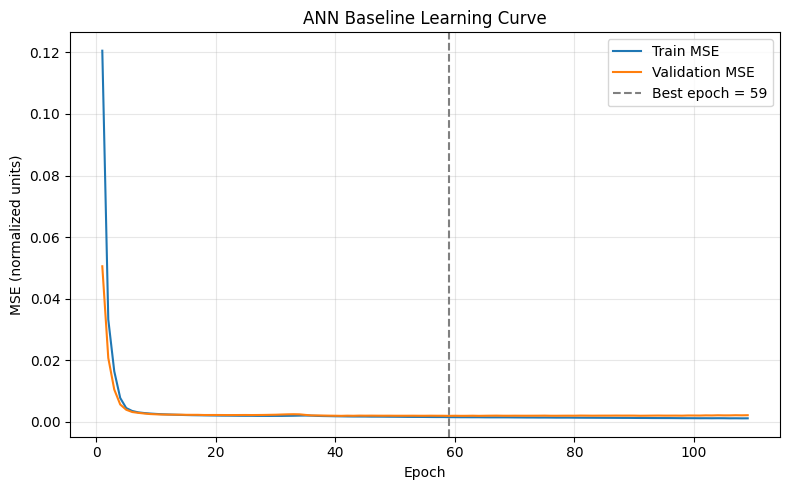


========== STEP 4 검증 결과 ==========
학습 epoch 수: 109
최저 Validation Loss epoch: 59
최저 Validation MSE (정규화): 0.00186824
독립 Test 데이터 사용 여부: 아니오
저장된 모델 재평가: PASS

[Validation 성능 - 실제 물리 단위]
  variable      R2     MAE    RMSE unit
        L1 0.98913 0.24169 0.35454   mm
        L2 0.97291 0.44446 0.60193   mm
         H 0.99580 0.18179 0.23115   mm
Theta1_out 0.99761 0.51072 0.63332  deg
Theta2_out 0.99466 0.52159 0.70099  deg
        R1 0.89182 0.15542 0.22508   mm
        R2 0.62695 0.23187 0.41350   mm

저장 경로: /content/drive/MyDrive/Hat_ANN_GA_results
STEP 4: PASS (학습 및 저장 검증)


In [4]:

# ============================================================
# STEP 4. ANN 기준 모델 구축 · 학습 · 검증
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error
import tensorflow as tf

# ------------------------------------------------------------
# 1. 기존 전처리 결과 점검
# ------------------------------------------------------------
assert X_train.shape == (623, 5)
assert Y_train.shape == (623, 7)
assert X_val.shape == (134, 5)
assert Y_val.shape == (134, 7)

assert input_cols == [
    'L1', 'L2', 'H', 'theta1', 'theta2'
]

assert target_cols == [
    'L1', 'L2', 'H',
    'Theta1_out', 'Theta2_out', 'R1', 'R2'
]

assert all(
    np.isfinite(a).all()
    for a in (X_train, Y_train, X_val, Y_val)
)

assert X_scaler.n_features_in_ == 5
assert Y_scaler.n_features_in_ == 7

results_dir = Path(results_dir)
assert results_dir.is_dir()

# ------------------------------------------------------------
# 2. 난수 시드 고정
# ------------------------------------------------------------
SEED = 42

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)

# ------------------------------------------------------------
# 3. ANN 구성
#    입력 5개 / 은닉층 5개 / 출력 7개
# ------------------------------------------------------------
hidden_units = [64, 128, 128, 64, 32]

model = tf.keras.Sequential(
    name='hat_ann_baseline'
)

model.add(
    tf.keras.Input(
        shape=(5,),
        name='die_inputs'
    )
)

for i, units in enumerate(hidden_units, start=1):
    model.add(
        tf.keras.layers.Dense(
            units,
            activation='relu',
            name=f'hidden_{i}'
        )
    )

model.add(
    tf.keras.layers.Dense(
        7,
        activation='linear',
        name='formed_shape'
    )
)

# ------------------------------------------------------------
# 4. 학습 조건 설정
# ------------------------------------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='mse',
    metrics=['mae']
)

dense_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dense)
]

assert len(dense_layers) == 6
assert model.output_shape[-1] == 7

print("\n========== ANN 구조 ==========")
model.summary()

# ------------------------------------------------------------
# 5. Early Stopping 및 모델 저장
# ------------------------------------------------------------
model_path = (
    results_dir / 'ANN_baseline_best.keras'
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_path),
        monitor='val_loss',
        mode='min',
        save_best_only=True,
        verbose=0
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=50,
        restore_best_weights=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# 6. ANN 학습
#    Test 데이터는 사용하지 않음
# ------------------------------------------------------------
history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=500,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 7. 가장 좋은 모델 불러오기
# ------------------------------------------------------------
assert model_path.is_file(), \
    "최적 모델 저장 실패"

best_model = tf.keras.models.load_model(
    str(model_path)
)

history_df = pd.DataFrame(history.history)

history_df.index = np.arange(
    1, len(history_df) + 1
)
history_df.index.name = 'epoch'

history_df.to_csv(
    results_dir / 'ANN_baseline_history.csv'
)

best_epoch = int(
    history_df['val_loss'].idxmin()
)

best_val_loss = float(
    history_df['val_loss'].min()
)

loaded_val_loss = float(
    best_model.evaluate(
        X_val, Y_val, verbose=0
    )[0]
)

assert np.isclose(
    best_val_loss,
    loaded_val_loss,
    rtol=1e-3,
    atol=1e-6
), "저장 모델의 검증 손실 불일치"

# ------------------------------------------------------------
# 8. Train / Validation Loss 그래프
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df.index,
    history_df['loss'],
    label='Train MSE'
)

ax.plot(
    history_df.index,
    history_df['val_loss'],
    label='Validation MSE'
)

ax.axvline(
    best_epoch,
    linestyle='--',
    color='gray',
    label=f'Best epoch = {best_epoch}'
)

ax.set_xlabel('Epoch')
ax.set_ylabel('MSE (normalized units)')
ax.set_title('ANN Baseline Learning Curve')

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    results_dir / 'ANN_baseline_learning_curve.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. Validation 데이터 예측 및 역정규화
# ------------------------------------------------------------
Y_val_pred_scaled = best_model.predict(
    X_val,
    verbose=0
)

assert Y_val_pred_scaled.shape == (134, 7)

Y_val_pred = Y_scaler.inverse_transform(
    Y_val_pred_scaled
)

Y_val_true = Y_val_raw[
    target_cols
].to_numpy(dtype=float)

assert np.isfinite(Y_val_pred).all()

# ------------------------------------------------------------
# 10. 변수별 성능 평가 (실제 물리 단위)
# ------------------------------------------------------------
metrics = []

for j, col in enumerate(target_cols):

    true = Y_val_true[:, j]
    pred = Y_val_pred[:, j]

    metrics.append({
        'variable': col,
        'R2': r2_score(true, pred),
        'MAE': mean_absolute_error(true, pred),
        'RMSE': float(
            np.sqrt(np.mean((true - pred)**2))
        ),
        'unit': (
            'deg' if 'Theta' in col else 'mm'
        )
    })

metrics_df = pd.DataFrame(metrics)

metrics_df.to_csv(
    results_dir /
    'ANN_baseline_validation_metrics.csv',
    index=False
)

# ------------------------------------------------------------
# 11. 최종 검증 결과 출력
# ------------------------------------------------------------
print("\n========== STEP 4 검증 결과 ==========")

print("학습 epoch 수:", len(history_df))
print("최저 Validation Loss epoch:", best_epoch)

print(
    f"최저 Validation MSE (정규화): "
    f"{best_val_loss:.8f}"
)

print("독립 Test 데이터 사용 여부: 아니오")
print("저장된 모델 재평가: PASS")

print("\n[Validation 성능 - 실제 물리 단위]")
print(metrics_df.round(5).to_string(index=False))

print("\n저장 경로:", results_dir)
print("STEP 4: PASS (학습 및 저장 검증)")


========== Validation 성능 재검증 ==========
  variable  R2_score     MAE    RMSE
        L1   0.98913 0.24169 0.35454
        L2   0.97291 0.44446 0.60193
         H   0.99580 0.18179 0.23115
Theta1_out   0.99761 0.51072 0.63332
Theta2_out   0.99466 0.52159 0.70099
        R1   0.89182 0.15542 0.22508
        R2   0.62695 0.23187 0.41350
기존 결과 교차 검증: PASS


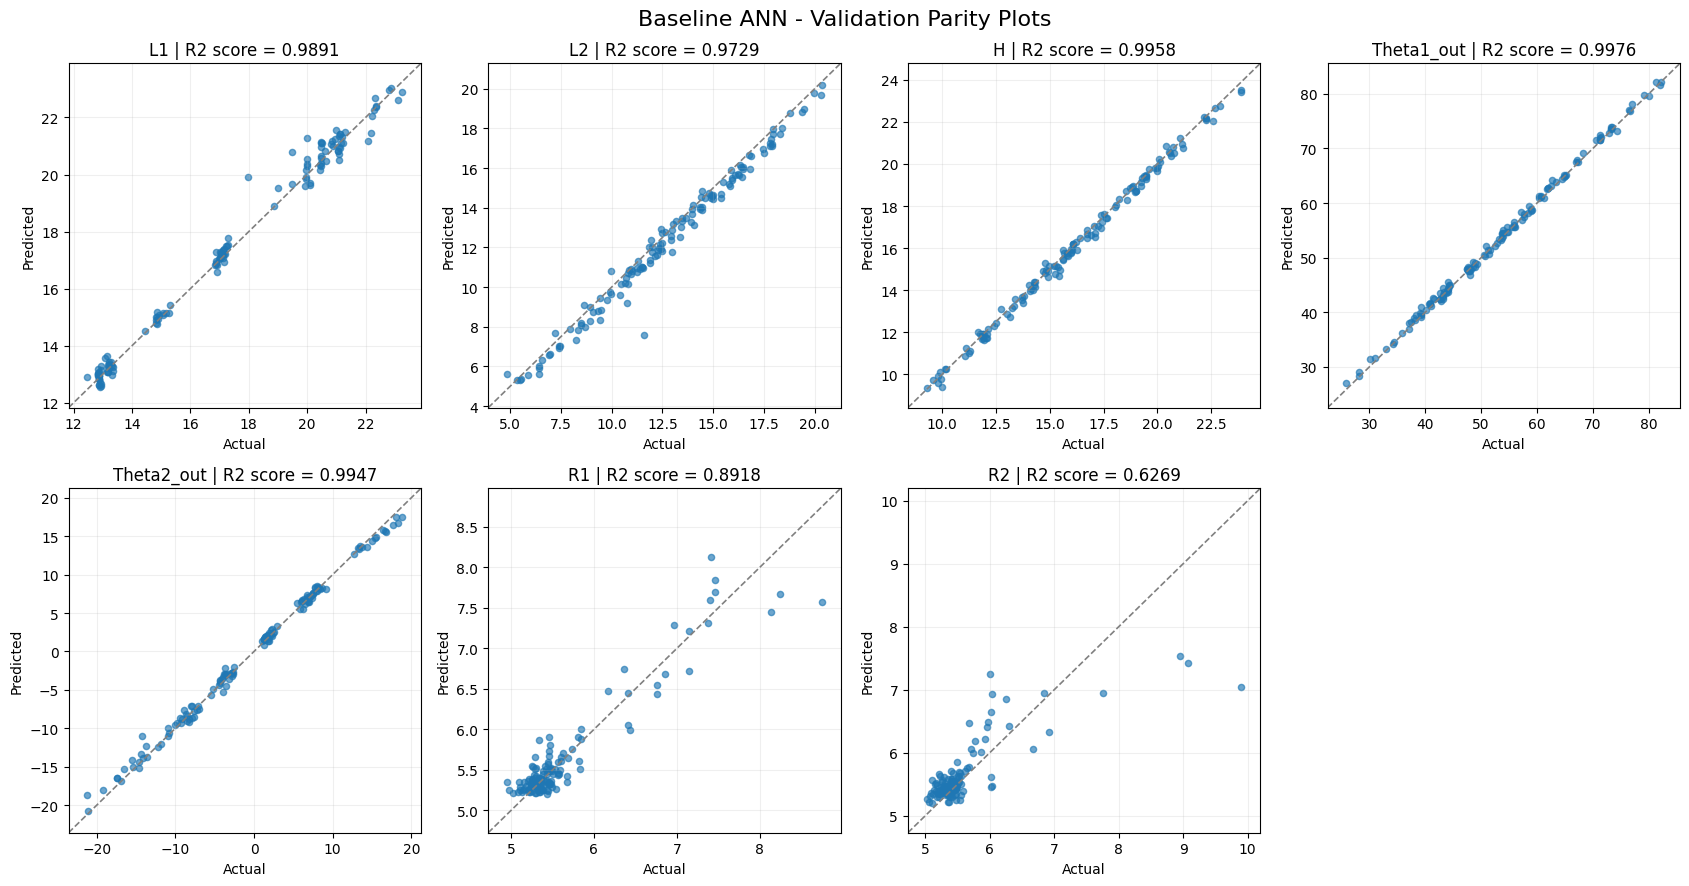


========== R2 오차 상위 10개 사례 ==========
 Model  R2_actual_mm  R2_predicted_mm  Error_mm  Absolute_error_mm  L1_die_mm  L2_die_mm  H_die_mm  theta1_die_deg  theta2_die_deg
   147        9.9036           7.0515   -2.8521             2.8521         12         17        10        -25.4633          3.3665
   328        9.0730           7.4283   -1.6446             1.6446         14         17        11        -27.7585         -3.3665
   112        8.9505           7.5405   -1.4100             1.4100         12         19        11        -27.7585         -3.0128
    83        5.9983           7.2560    1.2576             1.2576         12         21        15        -35.2176         -8.1301
   522        6.0326           6.9308    0.8983             0.8983         16         17        20        -39.4725        -19.4400
    41        7.7551           6.9451   -0.8100             0.8100         12         23        13        -33.6901         -7.4314
   131        5.6721           6.4701    0.7

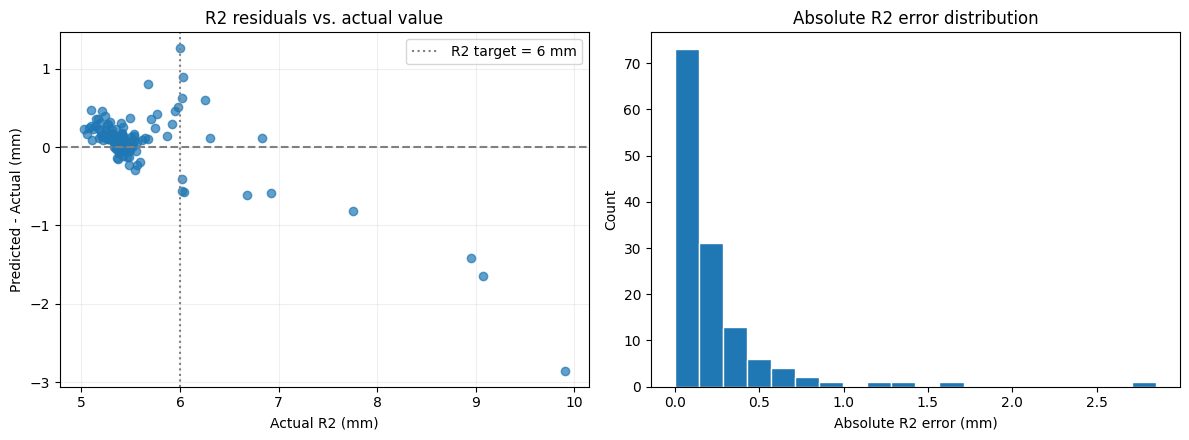


========== Learning Curve 요약 ==========
최적 epoch: 59
최적 epoch Train loss: 0.00145338
최적 epoch Validation loss: 0.00186824
마지막 epoch Train loss: 0.00107242
마지막 epoch Validation loss: 0.00208246

STEP 4-A: PASS (Validation 진단 완료, Test 미사용)


In [5]:

# ============================================================
# STEP 4-A. ANN 기준 모델 진단 (Validation only)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)
import tensorflow as tf

# ------------------------------------------------------------
# 1. 선행 단계 결과 검증
# ------------------------------------------------------------
results_dir = Path(results_dir)
model_file = results_dir / 'ANN_baseline_best.keras'

assert model_file.is_file(), "STEP 4 모델 파일이 없습니다."
assert X_val.shape == (134, 5)
assert Y_val.shape == (134, 7)
assert len(val_idx) == 134
assert len(Y_val_raw) == 134

assert np.array_equal(
    Y_val_raw.index.to_numpy(), val_idx
), "Validation 행 순서 불일치"

assert np.array_equal(
    input_df.iloc[val_idx]['Model'].to_numpy(),
    target_df.iloc[val_idx]['Model'].to_numpy()
), "Model 번호 불일치"

# ------------------------------------------------------------
# 2. 저장된 최적 ANN으로 Validation 예측
# ------------------------------------------------------------
baseline = tf.keras.models.load_model(str(model_file))

y_pred_scaled = baseline.predict(X_val, verbose=0)
assert y_pred_scaled.shape == (134, 7)

y_pred = Y_scaler.inverse_transform(y_pred_scaled)
y_true = Y_val_raw[target_cols].to_numpy(dtype=float)

assert np.isfinite(y_pred).all()

# ------------------------------------------------------------
# 3. 변수별 R2, MAE, RMSE 재계산
# ------------------------------------------------------------
metric_rows = []

for j, name in enumerate(target_cols):
    yt = y_true[:, j]
    yp = y_pred[:, j]

    metric_rows.append({
        'variable': name,
        'R2_score': r2_score(yt, yp),
        'MAE': mean_absolute_error(yt, yp),
        'RMSE': np.sqrt(mean_squared_error(yt, yp))
    })

metrics_check = pd.DataFrame(metric_rows)

print("========== Validation 성능 재검증 ==========")
print(metrics_check.round(5).to_string(index=False))

# 기존 STEP 4 결과와 교차 검증
previous_file = (
    results_dir / 'ANN_baseline_validation_metrics.csv'
)

assert previous_file.is_file()

previous = pd.read_csv(previous_file)
assert previous['variable'].tolist() == target_cols

assert np.allclose(
    previous[['R2', 'MAE', 'RMSE']].to_numpy(),
    metrics_check[
        ['R2_score', 'MAE', 'RMSE']
    ].to_numpy(),
    atol=1e-3,
    rtol=1e-3
), "기존 결과와 재계산 결과가 다릅니다."

print("기존 결과 교차 검증: PASS")

# ------------------------------------------------------------
# 4. 전체 7개 변수의 Parity Plot
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(17, 9))

for j, name in enumerate(target_cols):
    ax = axes.flat[j]

    yt = y_true[:, j]
    yp = y_pred[:, j]

    vmin = float(min(yt.min(), yp.min()))
    vmax = float(max(yt.max(), yp.max()))
    margin = max((vmax - vmin) * 0.06, 0.05)

    ax.scatter(yt, yp, s=20, alpha=0.65)

    ax.plot(
        [vmin-margin, vmax+margin],
        [vmin-margin, vmax+margin],
        linestyle='--',
        color='gray',
        linewidth=1.2
    )

    ax.set_xlim(vmin-margin, vmax+margin)
    ax.set_ylim(vmin-margin, vmax+margin)

    ax.set_title(
        f'{name} | R2 score = {r2_score(yt, yp):.4f}'
    )
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')
    ax.grid(alpha=0.2)

for ax in list(axes.flat)[len(target_cols):]:
    ax.set_visible(False)

fig.suptitle(
    'Baseline ANN - Validation Parity Plots',
    fontsize=16
)
fig.tight_layout()

fig.savefig(
    results_dir / 'ANN_baseline_validation_parity.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. 하부 곡률반경 R2의 예측 오차 조사
# ------------------------------------------------------------
j = target_cols.index('R2')

model_ids = input_df.iloc[val_idx]['Model'].to_numpy()

error_r2 = y_pred[:, j] - y_true[:, j]
abs_error_r2 = np.abs(error_r2)

r2_diagnosis = pd.DataFrame({
    'Model': model_ids,
    'R2_actual_mm': y_true[:, j],
    'R2_predicted_mm': y_pred[:, j],
    'Error_mm': error_r2,
    'Absolute_error_mm': abs_error_r2,
    'L1_die_mm': input_df.iloc[val_idx]['L1'].to_numpy(),
    'L2_die_mm': input_df.iloc[val_idx]['L2'].to_numpy(),
    'H_die_mm': input_df.iloc[val_idx]['H'].to_numpy(),
    'theta1_die_deg': input_df.iloc[val_idx]['theta1'].to_numpy(),
    'theta2_die_deg': input_df.iloc[val_idx]['theta2'].to_numpy()
})

r2_diagnosis = r2_diagnosis.sort_values(
    'Absolute_error_mm',
    ascending=False
)

r2_diagnosis.to_csv(
    results_dir / 'ANN_baseline_R2_validation_errors.csv',
    index=False
)

print("\n========== R2 오차 상위 10개 사례 ==========")
print(r2_diagnosis.head(10).round(4).to_string(index=False))

# ------------------------------------------------------------
# 6. R2가 큰 사례와 목표값 주변 사례의 오차 비교
# ------------------------------------------------------------
high = y_true[:, j] > 7.0

near_goal = (
    (y_true[:, j] >= 5.5) &
    (y_true[:, j] <= 6.5)
)

print("\n========== R2 세부 확인 ==========")

print("실제 R2 > 7 mm 사례 수:", high.sum())
print(
    "해당 사례 MAE (mm):",
    round(float(abs_error_r2[high].mean()), 4)
)

print(
    "나머지 사례 MAE (mm):",
    round(float(abs_error_r2[~high].mean()), 4)
)

print("실제 R2 = 5.5~6.5 mm 사례 수:", near_goal.sum())
print(
    "목표값 주변 MAE (mm):",
    round(float(abs_error_r2[near_goal].mean()), 4)
)

# ------------------------------------------------------------
# 7. R2 잔차 및 절대오차 분포
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(
    y_true[:, j], error_r2, alpha=0.7
)
axes[0].axhline(
    0, linestyle='--', color='gray'
)
axes[0].axvline(
    6.0, linestyle=':', color='gray',
    label='R2 target = 6 mm'
)
axes[0].set_xlabel('Actual R2 (mm)')
axes[0].set_ylabel('Predicted - Actual (mm)')
axes[0].set_title('R2 residuals vs. actual value')
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].hist(
    abs_error_r2, bins=20, edgecolor='white'
)
axes[1].set_xlabel('Absolute R2 error (mm)')
axes[1].set_ylabel('Count')
axes[1].set_title('Absolute R2 error distribution')

fig.tight_layout()

fig.savefig(
    results_dir / 'ANN_baseline_R2_error_analysis.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. 학습 이력 확인
# ------------------------------------------------------------
history_file = (
    results_dir / 'ANN_baseline_history.csv'
)

assert history_file.is_file()

h = pd.read_csv(history_file)

assert {'epoch', 'loss', 'val_loss'}.issubset(
    h.columns
)

min_pos = int(h['val_loss'].idxmin())

print("\n========== Learning Curve 요약 ==========")

print("최적 epoch:", int(h.loc[min_pos, 'epoch']))

print(
    "최적 epoch Train loss:",
    round(float(h.loc[min_pos, 'loss']), 8)
)

print(
    "최적 epoch Validation loss:",
    round(float(h.loc[min_pos, 'val_loss']), 8)
)

print(
    "마지막 epoch Train loss:",
    round(float(h.iloc[-1]['loss']), 8)
)

print(
    "마지막 epoch Validation loss:",
    round(float(h.iloc[-1]['val_loss']), 8)
)

print("\nSTEP 4-A: PASS (Validation 진단 완료, Test 미사용)")


Baseline 비교 지표: {'score': 0.02738, 'mean_nMAE': 0.02385, 'other6_nMAE': 0.01976, 'R2_MAE_mm': 0.23187, 'R2_R2score': 0.62695, 'R2_goal_MAE_mm': 0.32366, 'R2_high_MAE_mm': 1.67919}

STEP 5: 학습 실험 시작 - 8개 설정 x 2개 시드

Experiment 1/8: A_small_relu
  시작: A_small_relu, seed=42
  seed=42 | epoch=121 | score=0.02539 | R2 MAE=0.2176 mm | R2 score=0.6437
  시작: A_small_relu, seed=123
  seed=123 | epoch=280 | score=0.02556 | R2 MAE=0.2234 mm | R2 score=0.6000

Experiment 2/8: B_tanh
  시작: B_tanh, seed=42
  seed=42 | epoch=46 | score=0.02789 | R2 MAE=0.1967 mm | R2 score=0.7061
  시작: B_tanh, seed=123
  seed=123 | epoch=82 | score=0.02769 | R2 MAE=0.2140 mm | R2 score=0.6674

Experiment 3/8: C_relu_lr05
  시작: C_relu_lr05, seed=42
  seed=42 | epoch=47 | score=0.02780 | R2 MAE=0.2218 mm | R2 score=0.6463
  시작: C_relu_lr05, seed=123
  seed=123 | epoch=117 | score=0.02485 | R2 MAE=0.2193 mm | R2 score=0.6107

Experiment 4/8: D_tanh_lr05
  시작: D_tanh_lr05, seed=42
  seed=42 | epoch=92 | score=0.02752 | R

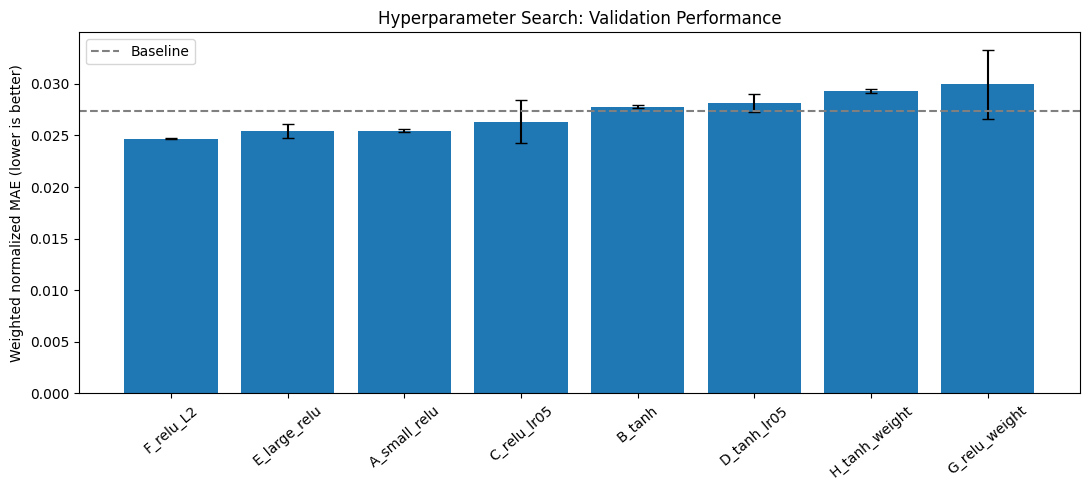


========== STEP 5 완료 =========
선정 모델: E_large_relu
선정 경로: /content/drive/MyDrive/Hat_ANN_GA_results/STEP5_hyperparameter_search/E_large_relu.keras


In [9]:
# ============================================================
# STEP 5. ANN 하이퍼파라미터 최적화 (Validation only)
# STEP 1~4-A를 실행한 Colab에서 새로운 셀에 붙여넣어 실행
# ============================================================
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import r2_score, mean_absolute_error

# 1. 기존 자료와 저장된 결과 검증
results_dir = Path(results_dir)
assert results_dir.is_dir()
assert X_train.shape == (623, 5) and Y_train.shape == (623, 7)
assert X_val.shape == (134, 5) and Y_val.shape == (134, 7)
assert input_cols == ['L1', 'L2', 'H', 'theta1', 'theta2']
assert target_cols == ['L1', 'L2', 'H', 'Theta1_out', 'Theta2_out', 'R1', 'R2']
assert np.isfinite(X_train).all() and np.isfinite(Y_train).all()
assert np.isfinite(X_val).all() and np.isfinite(Y_val).all()
assert np.all(Y_scaler.data_range_ > 0)
assert (results_dir / 'ANN_baseline_best.keras').is_file()
with np.load(results_dir / 'split_indices.npz') as saved_split:
    assert np.array_equal(saved_split['train'], train_idx), 'Train 분할이 바뀌었습니다.'
    assert np.array_equal(saved_split['validation'], val_idx), 'Validation 분할이 바뀌었습니다.'
assert np.array_equal(Y_val_raw.index.to_numpy(), val_idx)

# 모든 평가에서 동일한 단위·기준값 사용
VALID_TRUE = Y_val_raw[target_cols].to_numpy(dtype=np.float64)
SCALE = Y_scaler.data_range_.astype(np.float64)  # Train에서만 계산된 범위
SCORE_WEIGHTS = np.array([1, 1, 1, 1, 1, 1.5, 2.0], dtype=np.float64)
R2_COL = target_cols.index('R2')    # 곡률반경 R2 (결정계수 R²와 구분)
R1_COL = target_cols.index('R1')
near_goal = (VALID_TRUE[:, R2_COL] >= 5.5) & (VALID_TRUE[:, R2_COL] <= 6.5)
high_r2 = VALID_TRUE[:, R2_COL] > 7.0
assert near_goal.any() and high_r2.any()

# 모델 선발 지표: 원래 물리 단위 오차를 Train 범위로 무차원화한 MAE
# R1/R2의 중요도를 미리 높임 (R1=1.5, R2=2.0)
def evaluate_candidate(model):
    pred_scaled = model(tf.convert_to_tensor(X_val, dtype=tf.float32), training=False).numpy()
    assert pred_scaled.shape == (134, 7)
    pred = Y_scaler.inverse_transform(pred_scaled.astype(np.float64))
    assert np.isfinite(pred).all()
    abs_err = np.abs(pred - VALID_TRUE)
    nmae_by_var = abs_err.mean(axis=0) / SCALE
    result = {
        'score': float(np.average(nmae_by_var, weights=SCORE_WEIGHTS)),
        'mean_nMAE': float(nmae_by_var.mean()),
        'other6_nMAE': float(nmae_by_var[:6].mean()),
        'R2_MAE_mm': float(abs_err[:, R2_COL].mean()),
        'R2_R2score': float(r2_score(VALID_TRUE[:, R2_COL], pred[:, R2_COL])),
        'R2_goal_MAE_mm': float(abs_err[near_goal, R2_COL].mean()),
        'R2_high_MAE_mm': float(abs_err[high_r2, R2_COL].mean()),
    }
    per_var = pd.DataFrame({
        'variable': target_cols,
        'R2_score': [r2_score(VALID_TRUE[:, j], pred[:, j]) for j in range(7)],
        'MAE': abs_err.mean(axis=0),
        'RMSE': np.sqrt(((pred - VALID_TRUE) ** 2).mean(axis=0)),
        'normalized_MAE': nmae_by_var,
        'unit': ['mm', 'mm', 'mm', 'deg', 'deg', 'mm', 'mm']
    })
    return result, per_var

# 2. 기존 기준 모델 평가 (재학습하지 않음)
baseline_model = tf.keras.models.load_model(
    str(results_dir / 'ANN_baseline_best.keras'), compile=False
)
baseline_metrics, baseline_vars = evaluate_candidate(baseline_model)
baseline_reference = pd.read_csv(results_dir / 'ANN_baseline_validation_metrics.csv')
assert baseline_reference['variable'].tolist() == target_cols
baseline_r2_mae = float(baseline_reference.loc[
    baseline_reference['variable'] == 'R2', 'MAE'
].iloc[0])
assert np.isclose(baseline_metrics['R2_MAE_mm'], baseline_r2_mae, atol=1e-3), (
    '저장된 Baseline 성능과 현재 모델/Scaler의 결과가 다릅니다.'
)
print('Baseline 비교 지표:', {k: round(v, 5) for k, v in baseline_metrics.items()}, flush=True)
del baseline_model

# 3. 은닉층 5개 유지 및 다양한 조건 실험
CONFIGS = [
    dict(name='A_small_relu',   units=[32,64,64,32,16],     act='relu', lr=1e-3, l2=0.0, weighted=False),
    dict(name='B_tanh',         units=[64,128,128,64,32],  act='tanh', lr=1e-3, l2=0.0, weighted=False),
    dict(name='C_relu_lr05',    units=[64,128,128,64,32],  act='relu', lr=5e-4, l2=0.0, weighted=False),
    dict(name='D_tanh_lr05',    units=[64,128,128,64,32],  act='tanh', lr=5e-4, l2=0.0, weighted=False),
    dict(name='E_large_relu',   units=[128,128,128,64,32], act='relu', lr=5e-4, l2=0.0, weighted=False),
    dict(name='F_relu_L2',      units=[64,128,128,64,32],  act='relu', lr=1e-3, l2=1e-5, weighted=False),
    dict(name='G_relu_weight',  units=[64,128,128,64,32],  act='relu', lr=1e-3, l2=0.0, weighted=True),
    dict(name='H_tanh_weight',  units=[64,128,128,64,32],  act='tanh', lr=1e-3, l2=0.0, weighted=True),
]
SEEDS = [42, 123]

# Weighted loss는 입력/출력 0~1 스케일을 유지하면서 R1/R2 오차에 가중치 부여
@tf.keras.utils.register_keras_serializable(package='HatANN')
def weighted_shape_mse(y_true, y_pred):
    weights = tf.cast(tf.constant([1., 1., 1., 1., 1., 1.5, 2.]), y_pred.dtype)
    return tf.reduce_mean(tf.square(y_true-y_pred)*weights, axis=-1)

def make_model(cfg):
    net = tf.keras.Sequential(name='hat_' + cfg['name'])
    net.add(tf.keras.Input(shape=(5,)))
    for units in cfg['units']:
        net.add(tf.keras.layers.Dense(
            units, activation=cfg['act'],
            kernel_regularizer=(tf.keras.regularizers.l2(cfg['l2']) if cfg['l2'] else None)
        ))
    net.add(tf.keras.layers.Dense(7, activation='linear'))
    net.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=cfg['lr']),
        loss=weighted_shape_mse if cfg['weighted'] else 'mse',
        metrics=['mae']
    )
    assert len([layer for layer in net.layers if isinstance(layer, tf.keras.layers.Dense)]) == 6
    return net

# 4. 학습, 모델별 2회 반복, Validation 성능 기록
# 주의: 실행 후 실제 학습이 끝나야 STEP 5: PASS가 출력됩니다.
# 기존 STEP 5 셀의 코드 전체를 교체해야 합니다.
step5_dir = results_dir / 'STEP5_hyperparameter_search'
step5_dir.mkdir(exist_ok=True)
trial_rows = []
var_rows = []

print(f'\nSTEP 5: 학습 실험 시작 - {len(CONFIGS)}개 설정 x {len(SEEDS)}개 시드', flush=True)
for cfg_number, cfg in enumerate(CONFIGS, start=1):
    best_cfg_score = np.inf
    print('\n' + '='*55)
    print(f'Experiment {cfg_number}/{len(CONFIGS)}:', cfg['name'], flush=True)
    for seed in SEEDS:
        print(f'  시작: {cfg["name"]}, seed={seed}', flush=True)
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        net = make_model(cfg)
        callback = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', mode='min', patience=50,
            restore_best_weights=True
        )
        history = net.fit(
            X_train, Y_train,
            validation_data=(X_val, Y_val),
            epochs=500, batch_size=32, shuffle=True,
            callbacks=[callback], verbose=0
        )
        hist = pd.DataFrame(history.history)
        best_epoch = int(hist['val_loss'].idxmin()) + 1
        # L2 정규화·가중 손실에서는 val_loss 값의 의미가 달라지므로
        # 후보 간 순위는 아래 공통의 물리 단위 지표 score로 평가
        res, per_var = evaluate_candidate(net)
        res.update(name=cfg['name'], seed=seed,
                   epochs=len(hist), best_epoch=best_epoch,
                   best_val_loss=float(hist['val_loss'].min()))
        trial_rows.append(res)
        for rec in per_var.to_dict('records'):
            rec.update(name=cfg['name'], seed=seed)
            var_rows.append(rec)
        print(f"  seed={seed} | epoch={best_epoch} | score={res['score']:.5f} "
              f"| R2 MAE={res['R2_MAE_mm']:.4f} mm | R2 score={res['R2_R2score']:.4f}", flush=True)

        # 해당 구조에서 최저 score를 기록한 시드의 가중치와 이력만 보관
        if res['score'] < best_cfg_score:
            best_cfg_score = res['score']
            net.save(str(step5_dir / (cfg['name'] + '.keras')))
            hist.index = np.arange(1, len(hist)+1)
            hist.index.name = 'epoch'
            hist.to_csv(step5_dir / (cfg['name'] + '_history.csv'))
        # 중단 시에도 완료된 시드의 검증값을 복구할 수 있도록 즉시 기록
        pd.DataFrame(trial_rows).to_csv(step5_dir / 'trials_partial.csv', index=False)
        pd.DataFrame(var_rows).to_csv(step5_dir / 'per_variable_metrics_partial.csv', index=False)
        del net

# 5. 구조별 평균 성능 집계, 기준 모델과 비교
trials = pd.DataFrame(trial_rows)
trials.to_csv(step5_dir / 'trials.csv', index=False)
pd.DataFrame(var_rows).to_csv(step5_dir / 'per_variable_metrics.csv', index=False)
summary = trials.groupby('name', as_index=False).agg(
    score_mean=('score','mean'),
    score_std=('score','std'),
    other6_mean=('other6_nMAE','mean'),
    R2_MAE_mean=('R2_MAE_mm','mean'),
    R2_goal_MAE_mean=('R2_goal_MAE_mm','mean'),
    R2_R2score_mean=('R2_R2score','mean'),
)
summary = summary.sort_values('score_mean')
summary.to_csv(step5_dir / 'experiment_summary.csv', index=False)

print('\n========== 8개 실험 구조별 평균 성능 =========')
print(summary.round(5).to_string(index=False))
print('\n기준 모델 점수:', round(baseline_metrics['score'], 6))
print('기준 모델 R2 MAE (mm):', round(baseline_metrics['R2_MAE_mm'], 6))

# 모델 선발 조건: (a) 총점 개선, (b) R2 오차 악화 방지,
#                 (c) 나머지 6개 응답의 평균 정규화오차 10% 이상 악화 방지
eligible = summary[
    (summary['score_mean'] < baseline_metrics['score']) &
    (summary['R2_MAE_mean'] <= 1.05 * baseline_metrics['R2_MAE_mm']) &
    (summary['other6_mean'] <= 1.10 * baseline_metrics['other6_nMAE'])
]

winner = 'baseline'
best_path = results_dir / 'ANN_baseline_best.keras'
for _, row in eligible.iterrows():
    candidate_name = str(row['name'])
    candidate_path = step5_dir / (candidate_name + '.keras')
    candidate_model = tf.keras.models.load_model(str(candidate_path), compile=False)
    candidate_scores, _ = evaluate_candidate(candidate_model)
    del candidate_model
    if (candidate_scores['score'] < baseline_metrics['score'] and
        candidate_scores['R2_MAE_mm'] <= 1.05 * baseline_metrics['R2_MAE_mm'] and
        candidate_scores['other6_nMAE'] <= 1.10 * baseline_metrics['other6_nMAE']):
        winner, best_path = candidate_name, candidate_path
        break
if winner == 'baseline':
    print('\n선정 기준을 통과한 새로운 구조/모델이 없어 기존 Baseline을 유지합니다.')
else:
    print('\n선정 구조:', winner)

assert best_path.is_file()
print('최종 선택 검증 시작:', winner, flush=True)
selected_model = tf.keras.models.load_model(str(best_path), compile=False)
selected_scores, selected_vars = evaluate_candidate(selected_model)
selected_vars.to_csv(step5_dir / 'selected_validation_metrics.csv', index=False)

# 최종 GA에서 불러올 모델의 저장 경로를 명시적으로 기록
metadata = {
    'winner': winner,
    'model_path': str(best_path),
    'selection_rule': 'mean weighted normalized MAE + R2/other-six guardrails',
    'input_columns': input_cols,
    'output_columns': target_cols,
    'train_size': len(X_train),
    'validation_size': len(X_val),
    'test_evaluated': False,
    'selected_validation_score': selected_scores,
}
with open(step5_dir / 'selected_model_info.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

# 6. 비교 그래프
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(summary['name'], summary['score_mean'], yerr=summary['score_std'], capsize=4)
ax.axhline(baseline_metrics['score'], linestyle='--', color='gray', label='Baseline')
ax.set_ylabel('Weighted normalized MAE (lower is better)')
ax.set_title('Hyperparameter Search: Validation Performance')
ax.tick_params(axis='x', rotation=40)
ax.legend()
fig.tight_layout()
fig.savefig(step5_dir / 'hyperparameter_comparison.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

print('\n========== STEP 5 완료 =========')
print('선정 모델:', winner)
print('선정 경로:', best_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
기존 최종 모델 Validation 재검증: PASS
선정 ANN: E_large_relu

========== STEP 6: 독립 Test 성능 =========
Train / Validation / Test: 623 134 134
Validation 종합 점수: 0.024911
Test 종합 점수      : 0.025909
  variable  R2_score     MAE    RMSE  normalized_MAE unit
        L1   0.98904 0.23197 0.32958         0.02148   mm
        L2   0.97639 0.38428 0.51360         0.02347   mm
         H   0.99698 0.17566 0.21583         0.01192   mm
Theta1_out   0.99726 0.46090 0.61385         0.00820  deg
Theta2_out   0.99641 0.54323 0.69454         0.01335  deg
        R1   0.77165 0.17839 0.31348         0.03995   mm
        R2   0.63928 0.19628 0.32195         0.04094   mm

Test 내 실제 R2=5.5~6.5mm 사례 수: 28 MAE: 0.261116384522256
Test 내 실제 R2>7mm 사례 수: 7 MAE: 0.41214100387360364


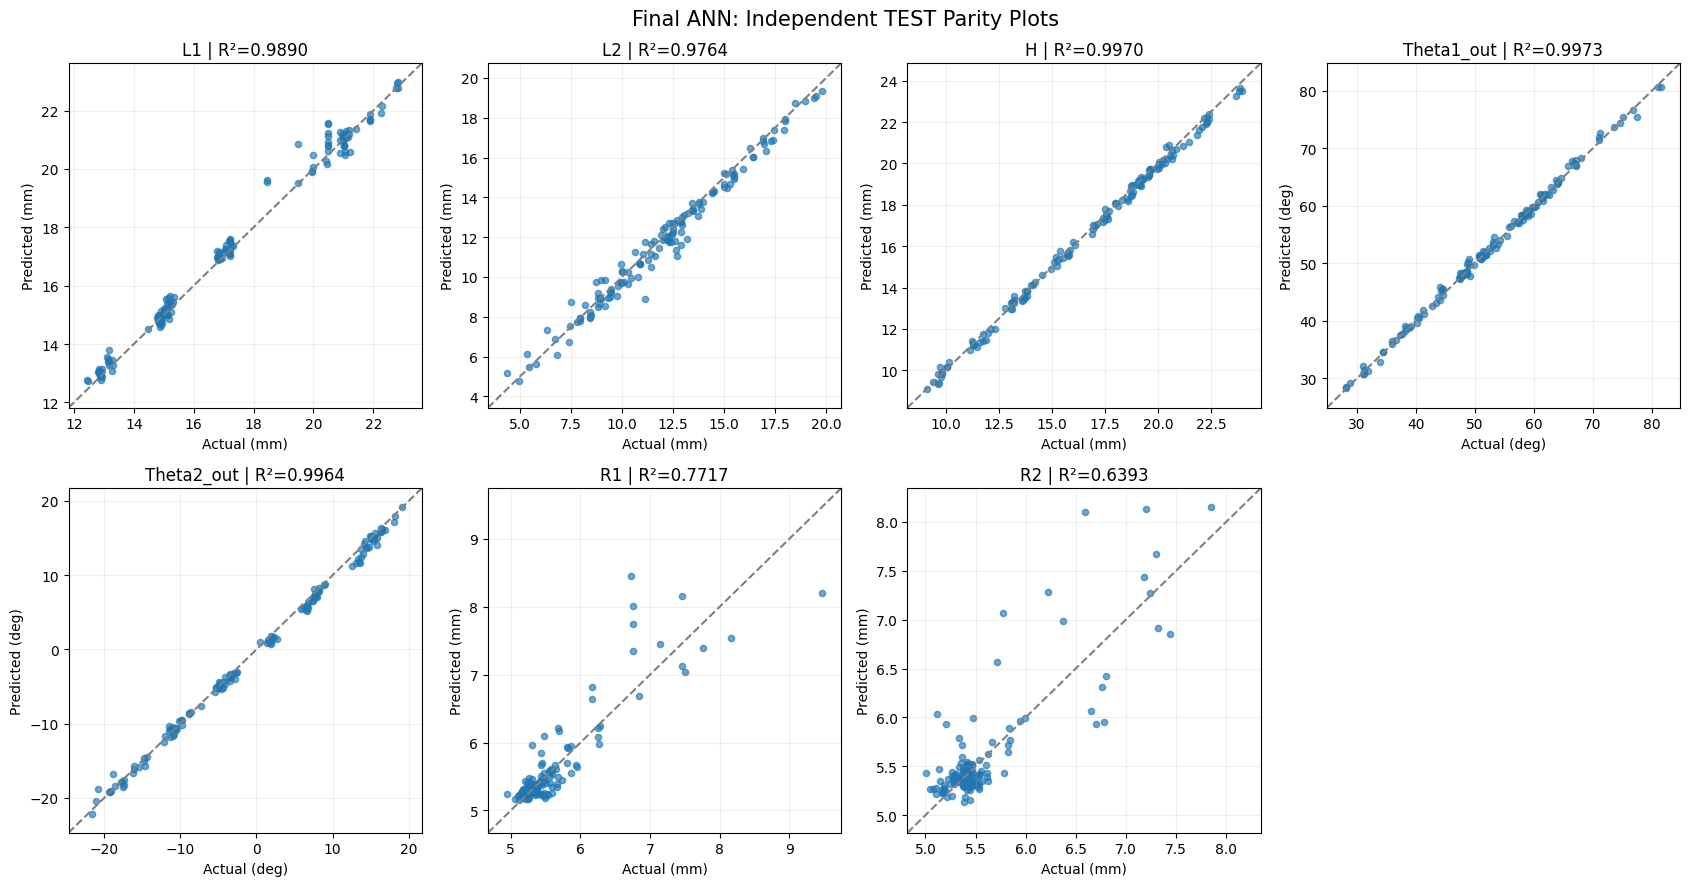

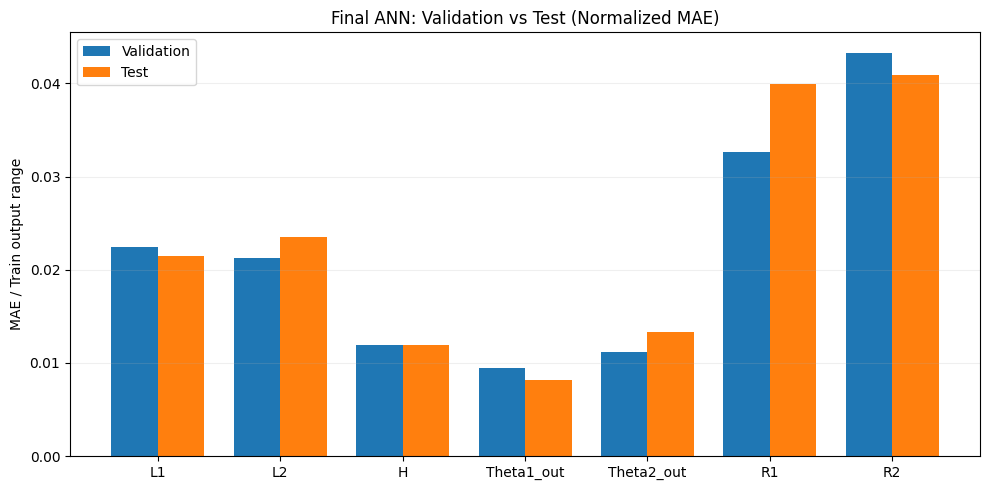


저장 경로: /content/drive/MyDrive/Hat_ANN_GA_results/STEP6_independent_test
파일: test_metrics.csv / test_predictions.csv / TEST_parity_7_outputs.png
파일: validation_vs_test_nMAE.png / test_evaluation_info.json
STEP 6: PASS (독립 Test 평가 완료; 예측 정확도는 수치로 판단)


In [13]:
# ================================================================
# STEP 6. Final ANN: untouched independent Test evaluation
# Run this cell ONLY after STEP 5 has selected the model.
# This script is standalone: it loads the saved CSV/splits/scalers.
# NO retraining, model selection, or hyperparameter tuning here.
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from google.colab import drive
from IPython.display import display


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def summarize_metrics(y_true, y_pred, names, scale):
    units = ['mm', 'mm', 'mm', 'deg', 'deg', 'mm', 'mm']
    assert y_true.shape == y_pred.shape and y_true.shape[1] == len(names) == 7
    rows = []
    for j, name in enumerate(names):
        actual, pred = y_true[:, j], y_pred[:, j]
        rows.append({
            'variable': name,
            'R2_score': float(r2_score(actual, pred)),
            'MAE': float(mean_absolute_error(actual, pred)),
            'RMSE': float(np.sqrt(mean_squared_error(actual, pred))),
            'normalized_MAE': float(np.mean(np.abs(actual - pred)) / scale[j]),
            'unit': units[j]
        })
    return pd.DataFrame(rows)


def main():
    # 1. Google Drive and saved artifact inspection
    drive.mount('/content/drive')
    root = Path('/content/drive/MyDrive')
    results_dir = root / 'Hat_ANN_GA_results'
    search_dir = results_dir / 'STEP5_hyperparameter_search'
    out_dir = results_dir / 'STEP6_independent_test'
    input_file = root / 'input.csv'
    target_file = root / 'target.csv'
    index_file = results_dir / 'split_indices.npz'
    x_scaler_file = results_dir / 'X_scaler.joblib'
    y_scaler_file = results_dir / 'Y_scaler.joblib'
    info_file = search_dir / 'selected_model_info.json'
    val_metrics_file = search_dir / 'selected_validation_metrics.csv'

    for f in [input_file, target_file, index_file,
              x_scaler_file, y_scaler_file, info_file, val_metrics_file]:
        assert f.is_file(), f'필수 파일이 없습니다: {f}'

    with open(info_file, encoding='utf-8') as f:
        info = json.load(f)

    input_cols = ['L1', 'L2', 'H', 'theta1', 'theta2']
    output_cols = ['L1', 'L2', 'H', 'Theta1_out', 'Theta2_out', 'R1', 'R2']
    assert info['input_columns'] == input_cols, 'STEP 5 입력변수 정의 불일치'
    assert info['output_columns'] == output_cols, 'STEP 5 출력변수 정의 불일치'
    assert info['winner'] == 'E_large_relu', '지난번에 검증한 선정 모델과 다릅니다. 다시 확인하세요.'
    model_file = Path(info['model_path'])
    assert model_file.is_file(), f'선정된 모델 파일이 없습니다: {model_file}'
    assert model_file.resolve() == (search_dir / 'E_large_relu.keras').resolve(), '선정 모델 경로 확인 필요'

    # Exact input/source fingerprints, checked on subsequent runs
    source_hashes = {
        'input_csv': sha256_file(input_file),
        'target_csv': sha256_file(target_file),
        'split_indices': sha256_file(index_file),
        'x_scaler': sha256_file(x_scaler_file),
        'y_scaler': sha256_file(y_scaler_file),
        'selected_ann': sha256_file(model_file),
    }

    report_file = out_dir / 'test_evaluation_info.json'
    if report_file.exists():
        with open(report_file, encoding='utf-8') as f:
            prior = json.load(f)
        assert prior['source_hashes'] == source_hashes, (
            '이전 Test 평가 이후 데이터/모델이 바뀌었습니다. 결과를 덮어쓰지 말고 원인을 점검하세요.'
        )
        print('STEP 6은 이미 완료되었습니다. Test를 다시 평가하지 않고 저장 결과를 표시합니다.')
        print('선정 모델:', prior['winner'])
        print('Test 종합점수:', round(prior['test_score'], 6))
        display(pd.read_csv(out_dir / 'test_metrics.csv').round(5))
        print('저장 경로:', out_dir)
        print('STEP 6: PASS (기존 결과 재사용)')
        return

    # 2. Read CSV and restore the *same* saved split/scalers
    data_x = pd.read_csv(input_file)
    data_y = pd.read_csv(target_file)
    assert data_x.shape == data_y.shape == (891, 8), '데이터 크기 불일치'
    assert data_x.columns.tolist() == ['Model'] + input_cols + ['R1', 'R2']
    assert data_y.columns.tolist() == ['Model'] + output_cols
    assert data_x['Model'].equals(data_y['Model']), 'Model 번호 및 순서 불일치'
    assert data_x['Model'].is_unique, 'Model 번호 중복'
    assert data_x.notna().all().all() and data_y.notna().all().all(), '결측값 발견'
    assert np.isfinite(data_x[input_cols].to_numpy(dtype=float)).all()
    assert np.isfinite(data_y[output_cols].to_numpy(dtype=float)).all()
    assert (data_x['R1'] == 5).all() and (data_x['R2'] == 6).all()

    with np.load(index_file) as archive:
        train_idx = archive['train']
        val_idx = archive['validation']
        test_idx = archive['test']

    assert (len(train_idx), len(val_idx), len(test_idx)) == (623, 134, 134)
    all_idx = np.concatenate([train_idx, val_idx, test_idx])
    assert np.array_equal(np.sort(all_idx), np.arange(891)), '분할 중 중복 또는 누락'

    x_scaler = joblib.load(x_scaler_file)
    y_scaler = joblib.load(y_scaler_file)
    assert x_scaler.n_features_in_ == 5 and y_scaler.n_features_in_ == 7
    assert np.all(y_scaler.data_range_ > 0)

    x_source = data_x[input_cols]
    y_source = data_y[output_cols]
    np.testing.assert_allclose(x_scaler.data_min_, x_source.iloc[train_idx].min().to_numpy(), atol=1e-8)
    np.testing.assert_allclose(x_scaler.data_max_, x_source.iloc[train_idx].max().to_numpy(), atol=1e-8)
    np.testing.assert_allclose(y_scaler.data_min_, y_source.iloc[train_idx].min().to_numpy(), atol=1e-8)
    np.testing.assert_allclose(y_scaler.data_max_, y_source.iloc[train_idx].max().to_numpy(), atol=1e-8)

    x_val = x_scaler.transform(x_source.iloc[val_idx]).astype(np.float32)
    x_test = x_scaler.transform(x_source.iloc[test_idx]).astype(np.float32)
    y_val_true = y_source.iloc[val_idx].to_numpy(dtype=np.float64)
    y_test_true = y_source.iloc[test_idx].to_numpy(dtype=np.float64)
    assert x_test.shape == (134, 5) and y_test_true.shape == (134, 7)

    # 3. Load model and *first* confirm saved Validation metrics
    selected = tf.keras.models.load_model(str(model_file), compile=False)
    assert selected.input_shape[-1] == 5 and selected.output_shape[-1] == 7
    val_prediction_norm = selected(tf.convert_to_tensor(x_val), training=False).numpy()
    assert val_prediction_norm.shape == (134, 7)
    y_val_pred = y_scaler.inverse_transform(val_prediction_norm.astype(np.float64))
    assert np.isfinite(y_val_pred).all()
    val_metrics = summarize_metrics(y_val_true, y_val_pred, output_cols, y_scaler.data_range_)
    recorded = pd.read_csv(val_metrics_file)
    assert recorded['variable'].tolist() == output_cols
    for metric in ['R2_score', 'MAE', 'RMSE', 'normalized_MAE']:
        np.testing.assert_allclose(
            val_metrics[metric].to_numpy(), recorded[metric].to_numpy(),
            atol=2e-4, rtol=2e-3,
            err_msg=f'STEP 5 Validation {metric} 재검증 불일치'
        )
    weights = np.array([1, 1, 1, 1, 1, 1.5, 2.0], dtype=np.float64)
    val_score = float(np.average(val_metrics['normalized_MAE'].to_numpy(), weights=weights))
    assert np.isclose(val_score, info['selected_validation_score']['score'], rtol=1e-3, atol=2e-4)
    print('기존 최종 모델 Validation 재검증: PASS')
    print('선정 ANN:', info['winner'])

    # 4. Exactly one evaluation pass of the reserved Test set
    pred_test_norm = selected(tf.convert_to_tensor(x_test), training=False).numpy()
    assert pred_test_norm.shape == (134, 7)
    y_test_pred = y_scaler.inverse_transform(pred_test_norm.astype(np.float64))
    assert np.isfinite(y_test_pred).all()
    test_metrics = summarize_metrics(y_test_true, y_test_pred, output_cols, y_scaler.data_range_)
    test_score = float(np.average(test_metrics['normalized_MAE'].to_numpy(), weights=weights))

    print('\n========== STEP 6: 독립 Test 성능 =========')
    print('Train / Validation / Test:', len(train_idx), len(val_idx), len(test_idx))
    print('Validation 종합 점수:', round(val_score, 6))
    print('Test 종합 점수      :', round(test_score, 6))
    print(test_metrics.round(5).to_string(index=False))

    # 5. Target-adjacent R2 diagnostic (not a re-selection criterion)
    j = output_cols.index('R2')
    near = (y_test_true[:, j] >= 5.5) & (y_test_true[:, j] <= 6.5)
    high = y_test_true[:, j] > 7.0
    goal_mae = float(np.abs(y_test_pred[near, j] - y_test_true[near, j]).mean()) if near.any() else None
    high_mae = float(np.abs(y_test_pred[high, j] - y_test_true[high, j]).mean()) if high.any() else None
    print('\nTest 내 실제 R2=5.5~6.5mm 사례 수:', int(near.sum()), 'MAE:', goal_mae)
    print('Test 내 실제 R2>7mm 사례 수:', int(high.sum()), 'MAE:', high_mae)

    # 6. Save reproducible results, without overwriting original model files
    out_dir.mkdir(parents=True, exist_ok=True)
    val_metrics.to_csv(out_dir / 'validation_metrics_rechecked.csv', index=False)
    test_metrics.to_csv(out_dir / 'test_metrics.csv', index=False)
    predictions = pd.DataFrame({'Model': data_x.iloc[test_idx]['Model'].to_numpy()})
    for j, col in enumerate(output_cols):
        predictions[f'{col}_actual'] = y_test_true[:, j]
        predictions[f'{col}_predicted'] = y_test_pred[:, j]
        predictions[f'{col}_error'] = y_test_pred[:, j] - y_test_true[:, j]
    predictions.to_csv(out_dir / 'test_predictions.csv', index=False)

    # Seven independent Parity Plots, with shared x/y limits in each panel
    fig, axs = plt.subplots(2, 4, figsize=(17, 9))
    for j, col in enumerate(output_cols):
        ax = axs.flat[j]
        yt, yp = y_test_true[:, j], y_test_pred[:, j]
        lower, upper = min(yt.min(), yp.min()), max(yt.max(), yp.max())
        margin = max((upper - lower) * 0.06, 0.05)
        ax.scatter(yt, yp, s=20, alpha=0.65)
        ax.plot([lower - margin, upper + margin], [lower - margin, upper + margin], '--', color='gray')
        ax.set(xlim=(lower - margin, upper + margin), ylim=(lower - margin, upper + margin),
               xlabel=f'Actual ({test_metrics.iloc[j]["unit"]})',
               ylabel=f'Predicted ({test_metrics.iloc[j]["unit"]})',
               title=f'{col} | R²={test_metrics.iloc[j]["R2_score"]:.4f}')
        ax.grid(alpha=0.2)
    axs.flat[-1].axis('off')
    fig.suptitle('Final ANN: Independent TEST Parity Plots', fontsize=15)
    fig.tight_layout()
    fig.savefig(out_dir / 'TEST_parity_7_outputs.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Compare normalized MAE; raw-unit MAEs cannot be compared across variables
    fig, ax = plt.subplots(figsize=(10, 5))
    pos = np.arange(7)
    ax.bar(pos - 0.19, val_metrics['normalized_MAE'], width=0.38, label='Validation')
    ax.bar(pos + 0.19, test_metrics['normalized_MAE'], width=0.38, label='Test')
    ax.set_xticks(pos, output_cols)
    ax.set_ylabel('MAE / Train output range')
    ax.set_title('Final ANN: Validation vs Test (Normalized MAE)')
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    fig.savefig(out_dir / 'validation_vs_test_nMAE.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    summary = {
        'timestamp_utc': datetime.now(timezone.utc).isoformat(),
        'winner': info['winner'], 'model_path': str(model_file),
        'test_evaluated': True,
        'train_size': len(train_idx), 'validation_size': len(val_idx), 'test_size': len(test_idx),
        'validation_score': val_score, 'test_score': test_score,
        'R2_goal_band_count': int(near.sum()), 'R2_goal_band_MAE_mm': goal_mae,
        'R2_gt_7_count': int(high.sum()), 'R2_gt_7_MAE_mm': high_mae,
        'source_hashes': source_hashes,
        'note': 'Do not use independent Test scores to reselect/tune ANN or GA hyperparameters.'
    }
    # Write report last: it signals completion for safe re-runs
    with open(report_file, 'w', encoding='utf-8') as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)
    print('\n저장 경로:', out_dir)
    print('파일: test_metrics.csv / test_predictions.csv / TEST_parity_7_outputs.png')
    print('파일: validation_vs_test_nMAE.png / test_evaluation_info.json')
    print('STEP 6: PASS (독립 Test 평가 완료; 예측 정확도는 수치로 판단)')


if __name__ == '__main__':
    main()


Mounted at /content/drive
STEP 6 사용 파일 무결성: PASS (Test 예측 재실행 없음)
891개 입력 금형 기하학 검증: PASS | 최대 복원 오차: [0.0, 0.0, 6e-09, 0.0, 0.0]
ANN+목적함수 벡터화/개별 계산 교차 검증: PASS
목표 출력 순서: {'L1': np.float64(18.0), 'L2': np.float64(14.0), 'H': np.float64(10.0), 'Theta1_out': np.float64(40.0), 'Theta2_out': np.float64(0.0), 'R1': np.float64(5.5), 'R2': np.float64(6.0)}
목적함수 가중치: {'L1': np.float64(1.0), 'L2': np.float64(1.0), 'H': np.float64(2.0), 'Theta1_out': np.float64(3.0), 'Theta2_out': np.float64(4.0), 'R1': np.float64(3.0), 'R2': np.float64(3.0)}
GA 설정: 100개체 × 100세대 × 5회 독립 실행

========== GA 독립 실행 1/5 | seed=42 ==========
  GA  20/100 세대 | best J=1.427137
  GA  40/100 세대 | best J=1.424623
  GA  60/100 세대 | best J=1.424396
  GA  80/100 세대 | best J=1.423959
  GA 100/100 세대 | best J=1.423642
  최종 J = 1.423529 (GA만: 1.423640)

========== GA 독립 실행 2/5 | seed=123 ==========
  GA  20/100 세대 | best J=1.424424
  GA  40/100 세대 | best J=1.423538
  GA  60/100 세대 | best J=1.423514
  GA  80/100 세대 | best J=1.423

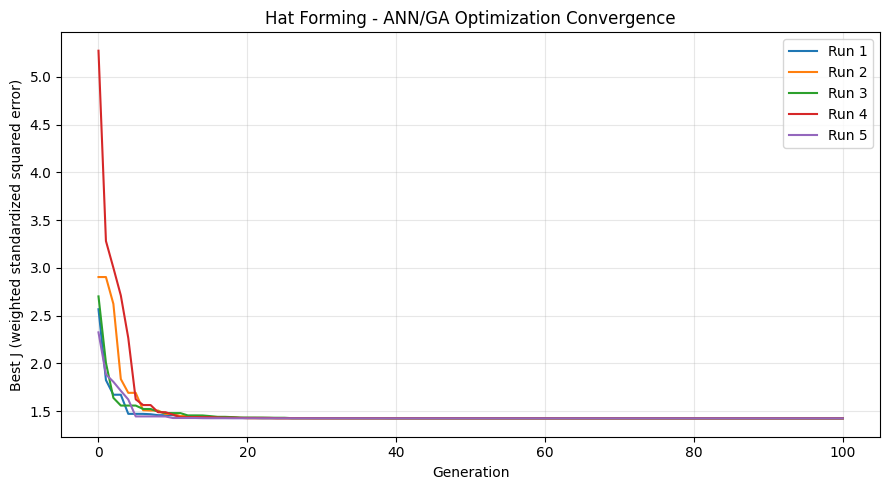

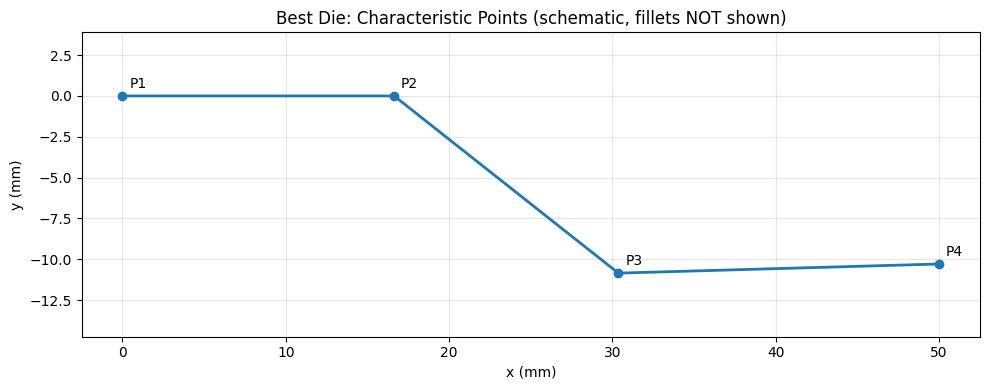


========== GA 최적 후보 상위 5개 ==========
 rank  run              origin       J       x2       x3        y3  offset  nearest_Train_design_distance
    1    5  local_refined_best 1.42350 16.63226 30.36002 -10.84855 0.55926                        0.15813
    2    4 GA_final_population 1.45841 17.17202 30.98035 -10.84931 0.56146                        0.16828
    3    2 GA_final_population 1.57082 15.92683 30.04577 -10.85287 0.56168                        0.16047
    4    2 GA_final_population 1.66382 16.62401 29.79577 -10.78131 0.56168                        0.14570
    5    5 GA_final_population 1.70666 16.65526 29.75438 -10.02614 0.55743                        0.12063

========== 최적 금형 입력 / 목표 제품 출력 비교 ==========
금형          L1: 16.632260
금형          L2: 19.639977
금형           H: 10.848546
금형      theta1: -38.318019
금형      theta2: 1.631098
          L1: 목표   18.0000 | ANN 예측   17.7466 | 오차   -0.2534 mm
          L2: 목표   14.0000 | ANN 예측   14.6657 | 오차   +0.6657 mm
           H: 목표   10.

In [1]:
# -*- coding: utf-8 -*-
"""STEP 7: Hat forming ANN surrogate + real-coded genetic algorithm.

Standalone Colab script. Needs previously saved STEP 2/5/6 assets in
Google Drive. Does NOT retrain the ANN, evaluate test labels, or run FEA.
"""
from __future__ import annotations

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.spatial.distance import cdist

# TensorFlow / Colab are imported inside main(), allowing local geometry tests.

INPUT_COLUMNS = ['L1', 'L2', 'H', 'theta1', 'theta2']
OUTPUT_COLUMNS = ['L1', 'L2', 'H', 'Theta1_out', 'Theta2_out', 'R1', 'R2']
DESIGN_COLUMNS = ['x2', 'x3', 'y3', 'offset']
TARGET = np.array([18.0, 14.0, 10.0, 40.0, 0.0, 5.5, 6.0], dtype=float)
# Author-selected weights, NOT supplied numerically by the paper.
# Correspond to OUTPUT_COLUMNS [L1, L2, H, Theta1, Theta2, R1, R2].
WEIGHTS = np.array([1.0, 1.0, 2.0, 3.0, 4.0, 3.0, 3.0], dtype=float)
BOUNDS = np.array([[12., 22.], [25., 33.], [-20., -10.], [-6., 6.]], dtype=float)
RANGES = BOUNDS[:, 1] - BOUNDS[:, 0]

POP_SIZE = 100
GENERATIONS = 100
GA_SEEDS = [42, 123, 2026, 31415, 27182]
ELITE_SIZE = 8
CROSSOVER_RATE = 0.75
GENE_MUTATION_RATE = 0.15
MUTATION_SD_FRACTION = 0.06
LOCAL_POLISH = True


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def as_population(designs):
    z = np.asarray(designs, dtype=float)
    if z.ndim == 1:
        assert z.shape == (4,), '설계변수는 4개여야 합니다.'
        z = z[None, :]
    assert z.ndim == 2 and z.shape[1] == 4
    assert np.isfinite(z).all()
    return z


def design_to_ann_input(designs):
    """X=[x2,x3,y3,offset] -> [L1,L2,H,theta1,theta2]."""
    d = as_population(designs)
    x2, x3, y3, off = d.T
    assert np.all(x3 > x2), 'P3.x는 P2.x보다 커야 합니다.'
    y4 = y3 + off
    L1 = x2
    L2 = 50.0 - x3
    H = -np.minimum(y3, y4)
    theta1 = np.rad2deg(np.arctan2(y3, x3 - x2))
    theta2 = np.rad2deg(np.arctan2(off, L2))
    return np.column_stack([L1, L2, H, theta1, theta2])


def ann_input_to_design(inputs):
    """Invert known die point geometry, for validation and training seeds."""
    a = np.asarray(inputs, dtype=float)
    assert a.ndim == 2 and a.shape[1] == 5
    x2 = a[:, 0]
    x3 = 50.0 - a[:, 1]
    y3 = (x3 - x2) * np.tan(np.deg2rad(a[:, 3]))
    off = a[:, 1] * np.tan(np.deg2rad(a[:, 4]))
    return np.column_stack([x2, x3, y3, off])


def verify_geometry(input_csv):
    x = pd.read_csv(input_csv)
    assert x.shape == (891, 8)
    assert x.columns.tolist() == ['Model'] + INPUT_COLUMNS + ['R1', 'R2']
    assert x['Model'].is_unique and x.notna().all().all()
    assert (x['R1'] == 5).all() and (x['R2'] == 6).all()
    expected = x[INPUT_COLUMNS].to_numpy(dtype=float)
    recovered = design_to_ann_input(ann_input_to_design(expected))
    max_err = np.max(np.abs(expected - recovered), axis=0)
    assert np.all(max_err < 1e-5), f'금형 관계식 불일치: {max_err}'
    d = ann_input_to_design(expected)
    assert np.all(d >= BOUNDS[:, 0] - 1e-5)
    assert np.all(d <= BOUNDS[:, 1] + 1e-5)
    expected_x2 = np.array([12, 14, 16, 20, 22])
    expected_x3 = np.array([25, 27, 29, 31, 33])
    np.testing.assert_array_equal(np.unique(np.rint(d[:, 0])), expected_x2)
    np.testing.assert_array_equal(np.unique(np.rint(d[:, 1])), expected_x3)
    np.testing.assert_array_equal(np.unique(np.rint(d[:, 2])), [-20, -18, -16, -14, -12, -10])
    np.testing.assert_array_equal(np.unique(np.rint(d[:, 3])), [-6, -3, -1, 1, 3, 6])
    print('891개 입력 금형 기하학 검증: PASS | 최대 복원 오차:',
          np.round(max_err, 9).tolist(), flush=True)
    return x


class SurrogateObjective:
    def __init__(self, model, x_scaler, y_scaler, train_y):
        self.model = model
        self.x_scaler = x_scaler
        self.y_scaler = y_scaler
        self.std = np.std(train_y, axis=0, ddof=0)
        assert self.std.shape == (7,) and np.all(self.std > 1e-8)
        assert x_scaler.n_features_in_ == 5 and y_scaler.n_features_in_ == 7

    def evaluate(self, designs):
        d = as_population(designs)
        inputs = design_to_ann_input(d)
        # Preserve scikit-learn's feature name/order metadata.
        normalized = self.x_scaler.transform(pd.DataFrame(inputs, columns=INPUT_COLUMNS))
        import tensorflow as tf
        predictions_normalized = self.model(
            tf.convert_to_tensor(normalized.astype(np.float32)),
            training=False
        ).numpy()
        predictions = self.y_scaler.inverse_transform(
            np.asarray(predictions_normalized, dtype=np.float64)
        )
        assert predictions.shape == (len(d), 7)
        assert np.isfinite(predictions).all(), 'ANN 예측값이 유한수가 아닙니다.'
        residual = (predictions - TARGET) / self.std
        j = np.sum(WEIGHTS * residual ** 2, axis=1)
        # Penalize any excursion outside the scaler's Train-only input range.
        # Usually zero within the supplied geometric bounds.
        excess = np.maximum(-normalized, 0) + np.maximum(normalized - 1, 0)
        extrap_penalty = 1e4 * np.sum(excess ** 2, axis=1)
        return j + extrap_penalty, predictions, inputs, extrap_penalty

    def costs(self, designs):
        return self.evaluate(designs)[0]

    def scalar_cost(self, design):
        return float(self.costs(design)[0])


def stochastic_universal_selection(costs, k, rng):
    """Rank-based stochastic universal sampling (SUS)."""
    n = len(costs)
    sorted_idx = np.argsort(costs)
    # Best rank n, worst rank 1; positive weights for all members.
    ranks = np.arange(n, 0, -1, dtype=float)
    cumul = np.cumsum(ranks)
    step = cumul[-1] / k
    pointers = rng.uniform(0.0, step) + np.arange(k) * step
    selected_sorted_positions = np.searchsorted(cumul, pointers, side='left')
    return sorted_idx[selected_sorted_positions]


def run_ga(objective, rng, training_designs, run_number):
    pop = rng.uniform(BOUNDS[:, 0], BOUNDS[:, 1], size=(POP_SIZE, 4))
    # Inject 20 genuine Train designs to start inside known design support.
    picked = rng.choice(len(training_designs), size=20, replace=False)
    # Inverse trigonometry produces ~1e-8 boundary roundoff; clip after geometric validation.
    pop[:20] = np.clip(training_designs[picked], BOUNDS[:, 0], BOUNDS[:, 1])
    assert np.all((pop >= BOUNDS[:, 0]) & (pop <= BOUNDS[:, 1]))

    scores = objective.costs(pop)
    evolution = [{'run': run_number, 'generation': 0,
                  'best_J': float(scores.min()), 'mean_J': float(scores.mean())}]

    for generation in range(1, GENERATIONS + 1):
        sorted_idx = np.argsort(scores)
        elite = pop[sorted_idx[:ELITE_SIZE]].copy()
        needed = POP_SIZE - ELITE_SIZE
        parent_idx = stochastic_universal_selection(scores, needed * 2, rng)
        parents = pop[parent_idx]
        children = np.empty((needed, 4), dtype=float)
        for i in range(needed):
            a, b = parents[2*i], parents[2*i + 1]
            if rng.random() < CROSSOVER_RATE:
                blend = rng.random(4)
                child = blend * a + (1.0 - blend) * b
            else:
                child = a.copy()
            mutate_mask = rng.random(4) < GENE_MUTATION_RATE
            child += mutate_mask * rng.normal(0, MUTATION_SD_FRACTION, size=4) * RANGES
            children[i] = np.clip(child, BOUNDS[:, 0], BOUNDS[:, 1])
        pop = np.vstack([elite, children])
        scores = objective.costs(pop)
        evolution.append({'run': run_number, 'generation': generation,
                          'best_J': float(scores.min()), 'mean_J': float(scores.mean())})
        assert evolution[-1]['best_J'] <= evolution[-2]['best_J'] + 1e-5, (
            'Elite 보존에도 목적함수 최솟값이 증가했습니다.'
        )
        if generation % 20 == 0 or generation == GENERATIONS:
            print(f'  GA {generation:3d}/{GENERATIONS} 세대 | best J={scores.min():.6f}', flush=True)
    best_idx = int(np.argmin(scores))
    return pop, scores, pop[best_idx].copy(), evolution


def build_row(design, objective, run_number, origin):
    d = as_population(design)
    costs, yhat, ann_input, penalty = objective.evaluate(d)
    rec = {'run': run_number, 'origin': origin,
           'J': float(costs[0]), 'input_range_penalty': float(penalty[0])}
    for col, val in zip(DESIGN_COLUMNS, d[0]):
        rec[col] = float(val)
    for col, val in zip(INPUT_COLUMNS, ann_input[0]):
        rec['die_' + col] = float(val)
    for col, val in zip(OUTPUT_COLUMNS, yhat[0]):
        rec['pred_' + col] = float(val)
        rec['error_' + col] = float(val - TARGET[OUTPUT_COLUMNS.index(col)])
    return rec


def choose_distinct_top5(pool, std):
    data = pool.sort_values('J').reset_index(drop=True)
    design_vals = data[DESIGN_COLUMNS].to_numpy(dtype=float)
    resp_vals = data[['pred_' + s for s in OUTPUT_COLUMNS]].to_numpy(dtype=float)
    design_norm = (design_vals - BOUNDS[:, 0]) / RANGES
    resp_norm = resp_vals / std
    for design_threshold, response_threshold in [(.07, .025), (.05, .015), (.03, .008), (.015, .003), (.025, 0.0)]:
        selected = []
        for i in range(len(data)):
            if all(
                np.linalg.norm(design_norm[i] - design_norm[j]) >= design_threshold and
                np.linalg.norm(resp_norm[i] - resp_norm[j]) >= response_threshold
                for j in selected
            ):
                selected.append(i)
            if len(selected) == 5:
                result = data.iloc[selected].copy()
                result.insert(0, 'rank', np.arange(1, 6))
                return result, (design_threshold, response_threshold)
    raise RuntimeError('금형 설계변수 기준으로도 서로 다른 후보 5개를 확보하지 못했습니다.')


def main():
    import tensorflow as tf
    from google.colab import drive

    drive.mount('/content/drive')
    root = Path('/content/drive/MyDrive')
    result_dir = root / 'Hat_ANN_GA_results'
    search_dir = result_dir / 'STEP5_hyperparameter_search'
    step6_dir = result_dir / 'STEP6_independent_test'
    out_dir = result_dir / 'STEP7_GA_optimization'
    input_csv, target_csv = root / 'input.csv', root / 'target.csv'
    split_file = result_dir / 'split_indices.npz'
    x_scaler_file = result_dir / 'X_scaler.joblib'
    y_scaler_file = result_dir / 'Y_scaler.joblib'
    meta_file = search_dir / 'selected_model_info.json'
    test_report_file = step6_dir / 'test_evaluation_info.json'

    required = [input_csv, target_csv, split_file, x_scaler_file,
                y_scaler_file, meta_file, test_report_file]
    for f in required:
        assert f.is_file(), f'필수 파일을 찾을 수 없습니다: {f}'

    with open(meta_file, encoding='utf-8') as f:
        meta = json.load(f)
    assert meta['input_columns'] == INPUT_COLUMNS
    assert meta['output_columns'] == OUTPUT_COLUMNS
    assert meta['winner'] == 'E_large_relu', '이전 단계에서 선택한 최종 모델과 다릅니다.'
    model_file = Path(meta['model_path'])
    assert model_file.resolve() == (search_dir / 'E_large_relu.keras').resolve()
    assert model_file.is_file()

    # Guard against changed input, split, scalers or model since STEP 6.
    expected_hashes = {
        'input_csv': sha256_file(input_csv),
        'target_csv': sha256_file(target_csv),
        'split_indices': sha256_file(split_file),
        'x_scaler': sha256_file(x_scaler_file),
        'y_scaler': sha256_file(y_scaler_file),
        'selected_ann': sha256_file(model_file)
    }
    with open(test_report_file, encoding='utf-8') as f:
        previous = json.load(f)
    assert previous['source_hashes'] == expected_hashes, (
        'STEP 6 이후 원본/분할/모델/스케일러 중 변경된 파일이 있습니다.'
    )
    print('STEP 6 사용 파일 무결성: PASS (Test 예측 재실행 없음)', flush=True)

    xdf = verify_geometry(input_csv)
    ydf = pd.read_csv(target_csv)
    assert ydf.shape == (891, 8)
    assert ydf.columns.tolist() == ['Model'] + OUTPUT_COLUMNS
    assert xdf['Model'].equals(ydf['Model'])
    assert np.isfinite(ydf[OUTPUT_COLUMNS].to_numpy(dtype=float)).all()

    with np.load(split_file) as archive:
        train_idx = archive['train']
        val_idx = archive['validation']
        test_idx = archive['test']
    assert (len(train_idx), len(val_idx), len(test_idx)) == (623, 134, 134)
    assert np.array_equal(np.sort(np.concatenate([train_idx, val_idx, test_idx])), np.arange(891))

    x_scaler = joblib.load(x_scaler_file)
    y_scaler = joblib.load(y_scaler_file)
    np.testing.assert_allclose(x_scaler.data_min_, xdf.iloc[train_idx][INPUT_COLUMNS].min().to_numpy())
    np.testing.assert_allclose(x_scaler.data_max_, xdf.iloc[train_idx][INPUT_COLUMNS].max().to_numpy())
    np.testing.assert_allclose(y_scaler.data_min_, ydf.iloc[train_idx][OUTPUT_COLUMNS].min().to_numpy())
    np.testing.assert_allclose(y_scaler.data_max_, ydf.iloc[train_idx][OUTPUT_COLUMNS].max().to_numpy())
    train_y = ydf.iloc[train_idx][OUTPUT_COLUMNS].to_numpy(dtype=float)
    training_designs = ann_input_to_design(xdf.iloc[train_idx][INPUT_COLUMNS].to_numpy(dtype=float))
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.models.load_model(str(model_file), compile=False)
    assert model.input_shape[-1] == 5 and model.output_shape[-1] == 7
    objective = SurrogateObjective(model, x_scaler, y_scaler, train_y)

    # Check objective and geometry on a batch before optimization.
    check_design = training_designs[:10]
    cost_batch = objective.costs(check_design)
    check_separate = np.array([objective.scalar_cost(d) for d in check_design])
    np.testing.assert_allclose(cost_batch, check_separate, rtol=5e-4, atol=1e-4)
    assert np.all(np.isfinite(cost_batch)) and np.all(cost_batch >= 0)
    print('ANN+목적함수 벡터화/개별 계산 교차 검증: PASS', flush=True)
    print('목표 출력 순서:', dict(zip(OUTPUT_COLUMNS, TARGET)))
    print('목적함수 가중치:', dict(zip(OUTPUT_COLUMNS, WEIGHTS)))
    print('GA 설정: 100개체 × 100세대 × 5회 독립 실행', flush=True)

    config = dict(population=POP_SIZE, generations=GENERATIONS,
                  seeds=GA_SEEDS, elite=ELITE_SIZE,
                  crossover=CROSSOVER_RATE, mutation=GENE_MUTATION_RATE,
                  local_polish=LOCAL_POLISH,
                  weights=WEIGHTS.tolist(), target=TARGET.tolist(),
                  bounds=BOUNDS.tolist())
    config_fingerprint = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode('utf-8')
    ).hexdigest()
    report_path = out_dir / 'GA_result_info.json'
    if report_path.is_file():
        old = json.loads(report_path.read_text(encoding='utf-8'))
        assert old['sources'] == expected_hashes and old['configuration_hash'] == config_fingerprint, (
            '이전 GA 실행과 데이터/설정이 달라졌습니다. 결과를 덮어쓰지 마세요.'
        )
        print('STEP 7은 이미 완료되었습니다. 기존 결과만 표시합니다.')
        print(pd.read_csv(out_dir / 'GA_top5_candidates.csv').round(5).to_string(index=False))
        print('STEP 7: PASS (저장된 결과 재사용)')
        return

    out_dir.mkdir(parents=True, exist_ok=True)
    runs = []
    hist_rows = []
    population_rows = []
    for run_number, seed in enumerate(GA_SEEDS, start=1):
        print(f'\n========== GA 독립 실행 {run_number}/{len(GA_SEEDS)} | seed={seed} ==========', flush=True)
        rng = np.random.default_rng(seed)
        pop, scores, best, history = run_ga(objective, rng, training_designs, run_number)
        initial_j = float(history[0]['best_J'])
        ga_j = float(objective.scalar_cost(best))
        assert ga_j <= initial_j + 1e-7
        rows = [build_row(d, objective, run_number, 'GA_final_population') for d in pop]
        population_rows.extend(rows)
        polished = best.copy()
        if LOCAL_POLISH:
            # Derivative-free bound-constrained local refinement. Optional enhancement,
            # applied only after GA, as in the accompanying paper.
            local = minimize(objective.scalar_cost, best,
                             method='Powell', bounds=BOUNDS.tolist(),
                             options={'maxiter': 50, 'maxfev': 450, 'xtol': 1e-3, 'ftol': 1e-5})
            if np.isfinite(local.fun):
                candidate = np.clip(local.x, BOUNDS[:, 0], BOUNDS[:, 1])
                if objective.scalar_cost(candidate) < ga_j - 1e-7:
                    polished = candidate
        polished_j = float(objective.scalar_cost(polished))
        assert polished_j <= ga_j + 1e-7
        population_rows.append(build_row(polished, objective, run_number, 'local_refined_best'))
        runs.append({'run': run_number, 'seed': seed,
                     'initial_best_J': initial_j,
                     'GA_best_J': ga_j,
                     'final_best_J': polished_j})
        hist_rows.extend(history)
        pd.DataFrame(runs).to_csv(out_dir / 'GA_runs_partial.csv', index=False)
        pd.DataFrame(hist_rows).to_csv(out_dir / 'GA_convergence_partial.csv', index=False)
        print(f'  최종 J = {polished_j:.6f} (GA만: {ga_j:.6f})', flush=True)

    runs_df = pd.DataFrame(runs)
    hist_df = pd.DataFrame(hist_rows)
    population_df = pd.DataFrame(population_rows)
    top5, diversity_thresholds = choose_distinct_top5(population_df, objective.std)
    assert len(top5) == 5 and np.all(np.isfinite(top5['J']))
    assert np.all(top5[DESIGN_COLUMNS].to_numpy() >= BOUNDS[:, 0] - 1e-8)
    assert np.all(top5[DESIGN_COLUMNS].to_numpy() <= BOUNDS[:, 1] + 1e-8)

    train_design_scaled = (training_designs - BOUNDS[:, 0]) / RANGES
    best_design_scaled = (top5[DESIGN_COLUMNS].to_numpy() - BOUNDS[:, 0]) / RANGES
    nearest = cdist(best_design_scaled, train_design_scaled).min(axis=1)
    top5['nearest_Train_design_distance'] = nearest
    if diversity_thresholds[1] == 0.0:
        print('주의: 출력 차이 기준을 만족하는 5개 해를 얻지 못해 설계변수 차이로만 다양성을 확보했습니다.')
    top5.to_csv(out_dir / 'GA_top5_candidates.csv', index=False)
    runs_df.to_csv(out_dir / 'GA_runs.csv', index=False)
    hist_df.to_csv(out_dir / 'GA_convergence.csv', index=False)
    population_df.to_csv(out_dir / 'GA_all_candidate_pool.csv', index=False)

    fig, ax = plt.subplots(figsize=(9, 5))
    for run_number in range(1, len(GA_SEEDS)+1):
        part = hist_df[hist_df['run'] == run_number]
        ax.plot(part['generation'], part['best_J'], label=f'Run {run_number}')
    ax.set(xlabel='Generation', ylabel='Best J (weighted standardized squared error)',
           title='Hat Forming - ANN/GA Optimization Convergence')
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_dir / 'GA_convergence_5_runs.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Schematic only: the corner fillets R1/R2 are deliberately not drawn.
    best_design = top5.iloc[0][DESIGN_COLUMNS].to_numpy(dtype=float)
    x2, x3, y3, off = best_design
    P = np.array([[0., 0.], [x2, 0.], [x3, y3], [50., y3 + off]])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(P[:, 0], P[:, 1], 'o-', linewidth=2)
    for k, (xx, yy) in enumerate(P, 1):
        ax.annotate(f'P{k}', (xx, yy), xytext=(5, 6), textcoords='offset points')
    ax.set(xlabel='x (mm)', ylabel='y (mm)',
           title='Best Die: Characteristic Points (schematic, fillets NOT shown)')
    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_dir / 'GA_best_die_characteristic_points.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    best_row = top5.iloc[0]
    print('\n========== GA 최적 후보 상위 5개 ==========', flush=True)
    print(top5[['rank', 'run', 'origin', 'J', *DESIGN_COLUMNS,
                'nearest_Train_design_distance']].round(5).to_string(index=False))
    print('\n========== 최적 금형 입력 / 목표 제품 출력 비교 ==========', flush=True)
    for v in INPUT_COLUMNS:
        print(f'금형 {v:>11s}: {float(best_row["die_"+v]):.6f}')
    for v, goal in zip(OUTPUT_COLUMNS, TARGET):
        actual = float(best_row['pred_' + v])
        unit = 'deg' if 'Theta' in v else 'mm'
        print(f'{v:>12s}: 목표 {goal:9.4f} | ANN 예측 {actual:9.4f} | 오차 {actual-goal:+9.4f} {unit}')

    # Report is the completion marker: write it only after all outputs are saved.
    report = {'status': 'complete', 'selected_ann': meta['winner'],
              'sources': expected_hashes, 'configuration_hash': config_fingerprint,
              'config': config, 'design_coordinates': DESIGN_COLUMNS,
              'ann_input_columns': INPUT_COLUMNS, 'ann_output_columns': OUTPUT_COLUMNS,
              'train_output_std_ddof0': objective.std.tolist(),
              'purpose': 'ANN-estimated optimization, not verified by new Abaqus FEA',
              'top5_diversity_thresholds': diversity_thresholds,
              'best_J': float(best_row['J']),
              'notes': ['Weights are course-design choices, not article-reported numerical values.',
                        'Continuous GA designs interpolate between FEA-generated training levels.',
                        'Fillet clearance, manufacturability and final FEA validation remain outstanding.',
                        'Test data was not used during GA optimization.']}
    report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
    print('\n저장 폴더:', out_dir)
    print('STEP 7: PASS (GA 실행/파일 저장/형상 제약 검증; FEA 물리 검증은 별도)', flush=True)


if __name__ == '__main__':
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 5/6/7 원본·모델·설정 해시 확인: PASS
기존 최적 금형 재예측 및 원목적함수 검증: PASS (J=1.423505)
STEP 8 가중치 민감도: 원본 가중치 + 4개 대안 비교
STEP 7 baseline 기존 결과 재사용; 나머지는 조건별 5회 독립 GA 실행

equal: GA 독립 실행 1/5 seed=42
equal run1: 25/100세대, best J=0.503255
equal run1: 50/100세대, best J=0.503226
equal run1: 75/100세대, best J=0.503226
equal run1: 100/100세대, best J=0.503226
equal run1 완료: J=0.503225

equal: GA 독립 실행 2/5 seed=123
equal run2: 25/100세대, best J=0.503283
equal run2: 50/100세대, best J=0.503029
equal run2: 75/100세대, best J=0.503008
equal run2: 100/100세대, best J=0.503008
equal run2 완료: J=0.503007

equal: GA 독립 실행 3/5 seed=2026
equal run3: 25/100세대, best J=0.504960
equal run3: 50/100세대, best J=0.503385
equal run3: 75/100세대, best J=0.503251
equal run3: 100/100세대, best J=0.503243
equal run3 완료: J=0.503224

equal: GA 독립 실행 4/5 seed=31415
equal run4: 25/100세대, best J=0.503563
equal run4: 50/10

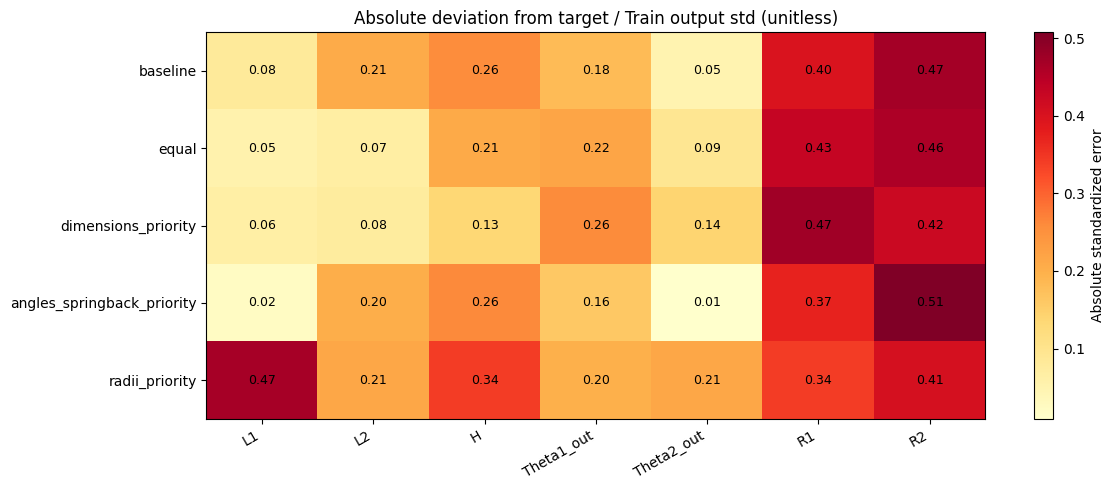

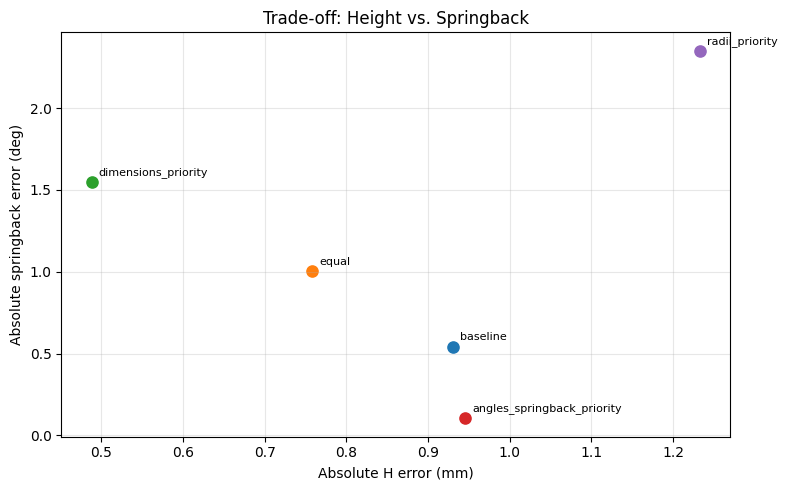


========= STEP 8: 5개 가중치 시나리오 비교 =========
                  scenario  scenario_J_div_sum_w  common_equal_standardized_MSE  common_original_weight_J  nearest_train_design_distance_normalized  error_L1  error_L2  error_H  error_Theta1_out  error_Theta2_out  error_R1  error_R2
                  baseline               0.08374                        0.07550                   1.42350                                   0.15813  -0.25340   0.66567  0.93022          -2.30361           0.53789   0.28860  -0.31264
                     equal               0.07186                        0.07186                   1.45904                                   0.16451   0.16845   0.21407  0.75816          -2.74469           1.00188   0.31280  -0.30643
       dimensions_priority               0.04551                        0.07412                   1.53885                                   0.18122   0.20369   0.24179  0.48804          -3.30017           1.55130   0.34431  -0.28177
angles_springback_priori

In [2]:
# -*- coding: utf-8 -*-
"""STEP 8: Hat-forming ANN/GA design weight-sensitivity verification.

Reuses the already-finalized Step 5 ANN, Step 2 Train-only scalers and
Step 7 baseline GA. Does not train, inspect test labels, or run Abaqus FEA.
Google Colab: %run /content/Hat_STEP8_Weight_Sensitivity.py
"""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.spatial.distance import cdist

INPUT_COLS = ['L1', 'L2', 'H', 'theta1', 'theta2']
OUTPUT_COLS = ['L1', 'L2', 'H', 'Theta1_out', 'Theta2_out', 'R1', 'R2']
DESIGN_COLS = ['x2', 'x3', 'y3', 'offset']
TARGET = np.array([18.0, 14.0, 10.0, 40.0, 0.0, 5.5, 6.0], dtype=float)
BOUNDS = np.array([[12., 22.], [25., 33.], [-20., -10.], [-6., 6.]])
WIDTH = BOUNDS[:, 1] - BOUNDS[:, 0]
BASE_WEIGHTS = np.array([1., 1., 2., 3., 4., 3., 3.])
# These are author-chosen SENSITIVITY scenarios, NOT numeric weights from the paper.
SCENARIOS = {
    'baseline': [1., 1., 2., 3., 4., 3., 3.],
    'equal': [1., 1., 1., 1., 1., 1., 1.],
    'dimensions_priority': [4., 4., 5., 2., 2., 1.5, 1.5],
    'angles_springback_priority': [1., 1., 2., 5., 8., 2., 2.],
    'radii_priority': [1., 1., 2., 2., 2., 7., 7.],
}
GA_SEEDS = [42, 123, 2026, 31415, 27182]
POP_SIZE = 100
GENERATIONS = 100
ELITES = 8
CROSSOVER_RATE = 0.75
GENE_MUTATION_RATE = 0.15
MUTATION_SD_FRACTION = 0.06
USE_LOCAL_POLISH = True


def file_hash(path):
    hash_obj = hashlib.sha256()
    with open(path, 'rb') as fd:
        for piece in iter(lambda: fd.read(1024 * 1024), b''):
            hash_obj.update(piece)
    return hash_obj.hexdigest()


def atomic_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, sort_keys=True), encoding='utf-8')
    tmp.replace(path)


def as_designs(z):
    z = np.asarray(z, dtype=np.float64)
    if z.ndim == 1:
        assert z.shape == (4,)
        z = z[None, :]
    assert z.ndim == 2 and z.shape[1] == 4 and np.isfinite(z).all()
    return z


def to_ann_inputs(z):
    z = as_designs(z)
    x2, x3, y3, off = z.T
    assert np.all(x3 > x2), '금형 특징점의 x좌표 순서가 잘못되었습니다.'
    L1 = x2
    L2 = 50. - x3
    y4 = y3 + off
    H = -np.minimum(y3, y4)
    theta1 = np.rad2deg(np.arctan2(y3, x3 - x2))
    theta2 = np.rad2deg(np.arctan2(off, L2))
    return np.column_stack([L1, L2, H, theta1, theta2])


def from_ann_inputs(inputs):
    a = np.asarray(inputs, dtype=float)
    assert a.ndim == 2 and a.shape[1] == 5
    x2 = a[:, 0]
    x3 = 50. - a[:, 1]
    y3 = (x3 - x2) * np.tan(np.deg2rad(a[:, 3]))
    off = a[:, 1] * np.tan(np.deg2rad(a[:, 4]))
    return np.column_stack([x2, x3, y3, off])


class ANNObjective:
    def __init__(self, model, scaler_x, scaler_y, std_train):
        self.model, self.scaler_x, self.scaler_y = model, scaler_x, scaler_y
        self.std = np.asarray(std_train, dtype=float)
        assert self.std.shape == (7,) and np.all(self.std > 1e-10)
        assert scaler_x.n_features_in_ == 5 and scaler_y.n_features_in_ == 7

    def predict(self, design):
        import tensorflow as tf
        a = to_ann_inputs(design)
        x_scaled = self.scaler_x.transform(pd.DataFrame(a, columns=INPUT_COLS))
        y_scaled = self.model(tf.convert_to_tensor(x_scaled.astype(np.float32)), training=False).numpy()
        y = self.scaler_y.inverse_transform(np.asarray(y_scaled, dtype=float))
        assert y.shape == (len(a), 7) and np.isfinite(y).all()
        # Same soft Train input-domain penalty as STEP 7.
        outside = np.maximum(-x_scaled, 0.) + np.maximum(x_scaled-1., 0.)
        penalty = 1e4 * np.square(outside).sum(axis=1)
        return y, a, penalty

    def evaluate(self, design, weights):
        weights = np.asarray(weights, dtype=float)
        assert weights.shape == (7,) and (weights >= 0).all() and weights.sum() > 0
        y, a, penalty = self.predict(design)
        residual_z = (y - TARGET) / self.std
        # Exactly same (UNnormalized) expression as STEP 7.
        values = (weights * residual_z**2).sum(axis=1) + penalty
        return values, y, a, penalty

    def one(self, design, weights):
        return float(self.evaluate(design, weights)[0][0])


def universal_rank_selection(costs, n_select, rng):
    order = np.argsort(costs)
    rank_weights = np.arange(len(costs), 0, -1, dtype=float)
    cumulative = np.cumsum(rank_weights)
    step = cumulative[-1] / n_select
    offsets = rng.uniform(0., step) + np.arange(n_select) * step
    return order[np.searchsorted(cumulative, offsets, side='left')]


def optimize_one_run(objective, train_designs, weights, seed, progress_label,
                     pop_size=POP_SIZE, generations=GENERATIONS, local_polish=USE_LOCAL_POLISH):
    """GA operators mirror STEP 7, with the same population, bounds and seeds."""
    rng = np.random.default_rng(seed)
    pop = rng.uniform(BOUNDS[:, 0], BOUNDS[:, 1], size=(pop_size, 4))
    inject_count = min(20, pop_size // 4)
    picked = rng.choice(len(train_designs), size=inject_count, replace=False)
    pop[:inject_count] = np.clip(train_designs[picked], BOUNDS[:, 0], BOUNDS[:, 1])
    scores = objective.evaluate(pop, weights)[0]
    records = [(0, float(scores.min()), float(scores.mean()))]
    for gen in range(1, generations + 1):
        ordered = np.argsort(scores)
        elites = pop[ordered[:ELITES]].copy()
        needed = pop_size - ELITES
        parents = pop[universal_rank_selection(scores, needed * 2, rng)]
        children = np.empty((needed, 4), dtype=float)
        for i in range(needed):
            a, b = parents[2 * i], parents[2 * i + 1]
            if rng.random() < CROSSOVER_RATE:
                lam = rng.random(4)
                child = lam * a + (1. - lam) * b
            else:
                child = a.copy()
            mutation = rng.random(4) < GENE_MUTATION_RATE
            child += mutation * rng.normal(0., MUTATION_SD_FRACTION, size=4) * WIDTH
            children[i] = np.clip(child, BOUNDS[:, 0], BOUNDS[:, 1])
        pop = np.vstack([elites, children])
        scores = objective.evaluate(pop, weights)[0]
        records.append((gen, float(scores.min()), float(scores.mean())))
        assert records[-1][1] <= records[-2][1] + 1e-5, 'GA elite 최저값 비단조'
        if gen % 25 == 0 or gen == generations:
            print(f'{progress_label}: {gen}/{generations}세대, best J={scores.min():.6f}', flush=True)
    best = pop[int(np.argmin(scores))].copy()
    before_polish = objective.one(best, weights)
    if local_polish:
        local = minimize(lambda u: objective.one(u, weights), best, method='Powell',
                         bounds=BOUNDS.tolist(),
                         options={'maxiter': 50, 'maxfev': 450, 'xtol': 1e-3, 'ftol': 1e-5})
        if np.isfinite(local.fun):
            candidate = np.clip(np.asarray(local.x), BOUNDS[:, 0], BOUNDS[:, 1])
            if objective.one(candidate, weights) < before_polish - 1e-7:
                best = candidate
    after_polish = objective.one(best, weights)
    assert after_polish <= before_polish + 1e-5
    assert np.all(best >= BOUNDS[:, 0] - 1e-8) and np.all(best <= BOUNDS[:, 1] + 1e-8)
    return best, before_polish, after_polish, records


def candidate_summary(objective, design, scenario, weights, training_designs):
    costs, ys, ann_ins, penalties = objective.evaluate(design, weights)
    d = as_designs(design)[0]
    y = ys[0]
    z = (y-TARGET) / objective.std
    dnorm = (d - BOUNDS[:, 0]) / WIDTH
    train_norm = (training_designs - BOUNDS[:, 0]) / WIDTH
    near = float(cdist(dnorm[None, :], train_norm).min())
    base_j = float(objective.evaluate(design, BASE_WEIGHTS)[0][0])
    return {
        'scenario': scenario,
        'scenario_J_raw': float(costs[0]),
        'scenario_J_div_sum_w': float(costs[0] / np.sum(weights)),
        'common_equal_standardized_MSE': float(np.mean(z*z)),
        'common_mean_abs_standardized_error': float(np.mean(np.abs(z))),
        'common_original_weight_J': base_j,
        'input_extrapolation_penalty': float(penalties[0]),
        'nearest_train_design_distance_normalized': near,
        **{f'design_{k}': float(v) for k, v in zip(DESIGN_COLS, d)},
        **{f'die_{k}': float(v) for k, v in zip(INPUT_COLS, ann_ins[0])},
        **{f'pred_{k}': float(v) for k, v in zip(OUTPUT_COLS, y)},
        **{f'error_{k}': float(v) for k, v in zip(OUTPUT_COLS, y-TARGET)},
        **{f'abs_std_error_{k}': float(v) for k, v in zip(OUTPUT_COLS, np.abs(z))},
    }


def main():
    import tensorflow as tf
    from google.colab import drive
    drive.mount('/content/drive')
    root = Path('/content/drive/MyDrive')
    results = root / 'Hat_ANN_GA_results'
    s5 = results / 'STEP5_hyperparameter_search'
    s6 = results / 'STEP6_independent_test'
    s7 = results / 'STEP7_GA_optimization'
    out = results / 'STEP8_weight_sensitivity'
    sources = {
        'input_csv': root / 'input.csv',
        'target_csv': root / 'target.csv',
        'split_indices': results / 'split_indices.npz',
        'x_scaler': results / 'X_scaler.joblib',
        'y_scaler': results / 'Y_scaler.joblib',
    }
    s5meta = s5 / 'selected_model_info.json'
    s6meta = s6 / 'test_evaluation_info.json'
    s7meta = s7 / 'GA_result_info.json'
    baseline_top = s7 / 'GA_top5_candidates.csv'
    baseline_runs = s7 / 'GA_runs.csv'
    for f in [*sources.values(), s5meta, s6meta, s7meta, baseline_top, baseline_runs]:
        assert f.is_file(), f'필수 기존 산출물이 없습니다: {f}'
    meta = json.loads(s5meta.read_text(encoding='utf-8'))
    assert meta['winner'] == 'E_large_relu', 'STEP 5 최종 ANN 선택이 달라졌습니다.'
    assert meta['input_columns'] == INPUT_COLS and meta['output_columns'] == OUTPUT_COLS
    model_path = Path(meta['model_path'])
    assert model_path.is_file() and model_path.resolve() == (s5 / 'E_large_relu.keras').resolve()
    sources['selected_ann'] = model_path
    hashes = {k: file_hash(v) for k, v in sources.items()}
    test_meta = json.loads(s6meta.read_text(encoding='utf-8'))
    old_ga_meta = json.loads(s7meta.read_text(encoding='utf-8'))
    assert test_meta['source_hashes'] == hashes, 'STEP 6 대비 파일이 변경됐습니다.'
    assert old_ga_meta['status'] == 'complete' and old_ga_meta['sources'] == hashes
    assert old_ga_meta['design_coordinates'] == DESIGN_COLS
    assert old_ga_meta['ann_input_columns'] == INPUT_COLS
    assert old_ga_meta['ann_output_columns'] == OUTPUT_COLS
    assert np.allclose(old_ga_meta['config']['weights'], BASE_WEIGHTS)
    assert np.allclose(old_ga_meta['config']['bounds'], BOUNDS)
    assert old_ga_meta['config']['seeds'] == GA_SEEDS
    assert old_ga_meta['config']['population'] == POP_SIZE
    assert old_ga_meta['config']['generations'] == GENERATIONS
    print('STEP 5/6/7 원본·모델·설정 해시 확인: PASS', flush=True)

    xdf = pd.read_csv(sources['input_csv'])
    ydf = pd.read_csv(sources['target_csv'])
    assert xdf.shape == ydf.shape == (891, 8)
    assert xdf.columns.tolist() == ['Model'] + INPUT_COLS + ['R1', 'R2']
    assert ydf.columns.tolist() == ['Model'] + OUTPUT_COLS
    assert xdf['Model'].equals(ydf['Model'])
    with np.load(sources['split_indices']) as saved:
        train_idx, val_idx, test_idx = [saved[k] for k in ('train', 'validation', 'test')]
    assert tuple(map(len, (train_idx, val_idx, test_idx))) == (623, 134, 134)
    np.testing.assert_array_equal(np.sort(np.concatenate([train_idx,val_idx,test_idx])), np.arange(891))
    scal_x = joblib.load(sources['x_scaler'])
    scal_y = joblib.load(sources['y_scaler'])
    np.testing.assert_allclose(scal_x.data_min_, xdf.iloc[train_idx][INPUT_COLS].min().to_numpy())
    np.testing.assert_allclose(scal_x.data_max_, xdf.iloc[train_idx][INPUT_COLS].max().to_numpy())
    np.testing.assert_allclose(scal_y.data_min_, ydf.iloc[train_idx][OUTPUT_COLS].min().to_numpy())
    np.testing.assert_allclose(scal_y.data_max_, ydf.iloc[train_idx][OUTPUT_COLS].max().to_numpy())
    train_in = xdf.iloc[train_idx][INPUT_COLS].to_numpy(dtype=float)
    train_out = ydf.iloc[train_idx][OUTPUT_COLS].to_numpy(dtype=float)
    train_designs = from_ann_inputs(train_in)
    np.testing.assert_allclose(to_ann_inputs(train_designs), train_in, rtol=0, atol=1e-5)
    assert np.all(train_designs >= BOUNDS[:, 0] - 1e-5)
    assert np.all(train_designs <= BOUNDS[:, 1] + 1e-5)
    model = tf.keras.models.load_model(str(model_path), compile=False)
    assert model.input_shape[-1] == 5 and model.output_shape[-1] == 7
    objective = ANNObjective(model, scal_x, scal_y, np.std(train_out, axis=0, ddof=0))
    np.testing.assert_allclose(objective.std, old_ga_meta['train_output_std_ddof0'], atol=1e-10, rtol=1e-10)

    old_top = pd.read_csv(baseline_top)
    assert old_top.shape[0] == 5 and int(old_top.loc[0,'rank']) == 1
    old_best_design = old_top.loc[0, DESIGN_COLS].to_numpy(dtype=float)
    rebuilt = objective.one(old_best_design, BASE_WEIGHTS)
    recorded = float(old_top.loc[0, 'J'])
    assert abs(rebuilt-recorded) < max(2e-3, 2e-3*abs(recorded)), (
        f'기존 GA 최적값과 재계산 목적함수가 일치하지 않습니다: {rebuilt} vs {recorded}'
    )
    print(f'기존 최적 금형 재예측 및 원목적함수 검증: PASS (J={rebuilt:.6f})', flush=True)

    scenario_arrays = {k: np.asarray(v, dtype=float) for k, v in SCENARIOS.items()}
    assert np.allclose(scenario_arrays['baseline'], BASE_WEIGHTS)
    for name,w in scenario_arrays.items():
        assert w.shape == (7,) and (w>0).all() and np.isfinite(w).all()
    setup = {'GA_seeds': GA_SEEDS, 'population': POP_SIZE, 'generations': GENERATIONS,
             'elites': ELITES, 'crossover': CROSSOVER_RATE, 'gene_mutation_rate': GENE_MUTATION_RATE,
             'mutation_sd_fraction': MUTATION_SD_FRACTION,
             'local_polish': USE_LOCAL_POLISH, 'scenarios': SCENARIOS,
             'output_cols': OUTPUT_COLS, 'target': TARGET.tolist(), 'bounds': BOUNDS.tolist(),
             'old_ga_config_hash': old_ga_meta['configuration_hash']}
    setup_sha = hashlib.sha256(json.dumps(setup, sort_keys=True).encode('utf-8')).hexdigest()
    manifest = {'sources': hashes, 'setup_sha256': setup_sha}
    out.mkdir(parents=True, exist_ok=True)
    manifest_file = out / 'run_manifest.json'
    if manifest_file.exists():
        assert json.loads(manifest_file.read_text(encoding='utf-8')) == manifest, (
            '이전 STEP 8 실행과 파일 또는 설정이 다릅니다. 기존 결과를 덮어쓰면 안 됩니다.'
        )
    else:
        atomic_json(manifest_file, manifest)
    checkpoint_dir = out / 'checkpoints'
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    print('STEP 8 가중치 민감도: 원본 가중치 + 4개 대안 비교', flush=True)
    print('STEP 7 baseline 기존 결과 재사용; 나머지는 조건별 5회 독립 GA 실행', flush=True)

    bests = []
    all_runs = []
    all_hist = []
    old_ga_runs = pd.read_csv(baseline_runs)
    assert old_ga_runs.shape[0] == len(GA_SEEDS)
    for _, oldrow in old_ga_runs.iterrows():
        run = int(oldrow['run'])
        assert int(oldrow['seed']) == GA_SEEDS[run-1]
        all_runs.append({'scenario':'baseline','run':run,'seed':int(oldrow['seed']),
                         'best_J_raw':float(oldrow['final_best_J']),
                         'best_J_div_sum_w':float(oldrow['final_best_J'])/BASE_WEIGHTS.sum(),
                         'reused_STEP7': True})
    bests.append(candidate_summary(objective, old_best_design, 'baseline', BASE_WEIGHTS, train_designs))

    for name, weights in scenario_arrays.items():
        if name == 'baseline':
            continue
        candidates = []
        for run, seed in enumerate(GA_SEEDS, start=1):
            chk = checkpoint_dir / f'{name}_run{run:02d}_seed{seed}.json'
            hist = checkpoint_dir / f'{name}_run{run:02d}_seed{seed}_history.csv'
            if chk.is_file():
                assert hist.is_file(), f'수렴이력 파일 누락: {hist}'
                data = json.loads(chk.read_text(encoding='utf-8'))
                assert data['scenario']==name and data['seed']==seed and data['run']==run
                assert data['manifest_sha256']==setup_sha
                design = np.asarray(data['design'], dtype=float)
                checked_J = objective.one(design, weights)
                assert abs(checked_J-data['best_J_raw']) < max(2e-3, 2e-3*abs(checked_J))
                print(f'{name} {run}/5: 저장된 결과 재사용 (J={checked_J:.6f})', flush=True)
            else:
                print(f'\n{name}: GA 독립 실행 {run}/{len(GA_SEEDS)} seed={seed}', flush=True)
                design, ga_J, checked_J, records = optimize_one_run(
                    objective, train_designs, weights, seed, f'{name} run{run}'
                )
                pd.DataFrame(records, columns=['generation','best_J_raw','mean_J_raw']).to_csv(hist,index=False)
                data = {'manifest_sha256':setup_sha, 'scenario':name,'run':run,'seed':seed,
                        'design':design.tolist(), 'GA_only_J_raw':ga_J, 'best_J_raw':checked_J}
                atomic_json(chk, data)
                print(f'{name} run{run} 완료: J={checked_J:.6f}', flush=True)
            candidates.append((checked_J,design.copy()))
            all_runs.append({'scenario':name,'run':run,'seed':seed,
                             'best_J_raw':float(checked_J),
                             'best_J_div_sum_w':float(checked_J/weights.sum()),
                             'reused_STEP7':False})
            rec = pd.read_csv(hist)
            assert {'generation','best_J_raw','mean_J_raw'}.issubset(rec.columns)
            assert len(rec)==GENERATIONS+1 and int(rec['generation'].iloc[-1])==GENERATIONS
            for _,rr in rec.iterrows():
                all_hist.append({'scenario':name,'run':run,'seed':seed,
                                 'generation':int(rr['generation']),
                                 'best_J_raw':float(rr['best_J_raw']),
                                 'best_J_div_sum_w':float(rr['best_J_raw']/weights.sum())})
        best_choice = min(candidates,key=lambda t:t[0])[1]
        bests.append(candidate_summary(objective,best_choice,name,weights,train_designs))

    result = pd.DataFrame(bests)
    assert result.shape[0] == len(SCENARIOS)
    assert set(result['scenario']) == set(SCENARIOS)
    assert np.all(np.isfinite(result.select_dtypes('number').to_numpy()))
    assert np.all(result[[f'design_{k}' for k in DESIGN_COLS]].to_numpy() >= BOUNDS[:,0]-1e-7)
    assert np.all(result[[f'design_{k}' for k in DESIGN_COLS]].to_numpy() <= BOUNDS[:,1]+1e-7)
    runs = pd.DataFrame(all_runs)
    stability = runs.groupby('scenario')['best_J_div_sum_w'].agg(['mean','std','min','max']).reset_index()
    stability.columns = ['scenario','run_J_div_sum_w_mean','run_J_div_sum_w_sd','run_J_div_sum_w_min','run_J_div_sum_w_max']
    result = result.merge(stability,on='scenario',validate='one_to_one')
    result.to_csv(out/'GA_weight_sensitivity_summary.csv',index=False)
    runs.to_csv(out/'GA_weight_sensitivity_runs.csv',index=False)
    pd.DataFrame(all_hist).to_csv(out/'GA_weight_sensitivity_convergence.csv',index=False)

    # Cross-score every candidate with EVERY weight vector: no objective-scale confusion.
    comparison = []
    for _, r in result.iterrows():
        d = np.array([r[f'design_{c}'] for c in DESIGN_COLS])
        for measure, w in scenario_arrays.items():
            raw = objective.one(d,w)
            comparison.append({'candidate':r['scenario'],'evaluated_by_weights':measure,
                               'J_raw':raw,'J_div_sum_w':raw/w.sum()})
    pd.DataFrame(comparison).to_csv(out/'GA_cross_weight_objective_matrix.csv',index=False)

    fig, ax = plt.subplots(figsize=(12,5))
    err_matrix = result[[f'abs_std_error_{c}' for c in OUTPUT_COLS]].to_numpy()
    image = ax.imshow(err_matrix, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(7),OUTPUT_COLS,rotation=30,ha='right')
    ax.set_yticks(range(len(result)),result['scenario'])
    for i in range(len(result)):
        for j in range(7):
            ax.text(j,i,f'{err_matrix[i,j]:.2f}',ha='center',va='center',fontsize=9)
    ax.set_title('Absolute deviation from target / Train output std (unitless)')
    fig.colorbar(image,ax=ax,label='Absolute standardized error')
    fig.tight_layout()
    fig.savefig(out/'GA_weight_sensitivity_errors.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)

    fig,ax=plt.subplots(figsize=(8,5))
    for _,r in result.iterrows():
        ax.scatter(abs(r['error_H']),abs(r['error_Theta2_out']),s=65)
        ax.annotate(r['scenario'],(abs(r['error_H']),abs(r['error_Theta2_out'])),
                    xytext=(5,5),textcoords='offset points',fontsize=8)
    ax.set(xlabel='Absolute H error (mm)',ylabel='Absolute springback error (deg)',
           title='Trade-off: Height vs. Springback')
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(out/'GA_weight_sensitivity_tradeoff.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)

    report = {'status':'complete','sources':hashes,'setup_sha256':setup_sha,
              'scenarios':SCENARIOS,'seeds':GA_SEEDS,
              'baseline_reused_from_step7':True,
              'selected_ann':'E_large_relu',
              'target_values_in_OUTPUT_COLS_order':TARGET.tolist(),
              'notes':['Alternative weights chosen for sensitivity study, not published weights.',
                       'Only objective within SAME weight scenario is directly comparable; common errors permit cross-scenario comparison.',
                       'Five independent GA runs per alternative; baseline reused from STEP7 five runs.',
                       'No refit after Test evaluation, and no new Abaqus/FEA run.',
                       'Die fillet clearance and manufacturing feasibility were not physically verified.',
                       'ANN radius errors from STEP6 remain a limiting uncertainty.']}
    atomic_json(out/'GA_weight_sensitivity_report.json',report)

    print('\n========= STEP 8: 5개 가중치 시나리오 비교 =========',flush=True)
    shown = ['scenario','scenario_J_div_sum_w','common_equal_standardized_MSE',
             'common_original_weight_J','nearest_train_design_distance_normalized',
             'error_L1','error_L2','error_H','error_Theta1_out','error_Theta2_out','error_R1','error_R2']
    print(result[shown].round(5).to_string(index=False),flush=True)
    print('\n출력 그래프: GA_weight_sensitivity_errors.png / GA_weight_sensitivity_tradeoff.png')
    print('출력 폴더:',out)
    print('STEP 8: PASS (가중치 민감도 수치검증 완료; ABAQUS/실험 검증 미수행)',flush=True)


if __name__ == '__main__':
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 9: 기존 결과 검증 시작
STEP 2·7·8 원본 해시 / 설계변수 / 목적함수 교차검증: PASS


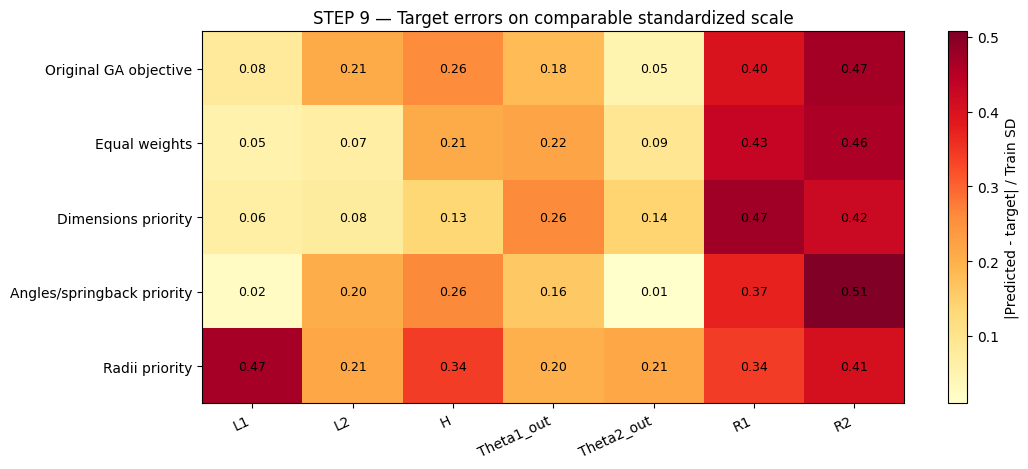

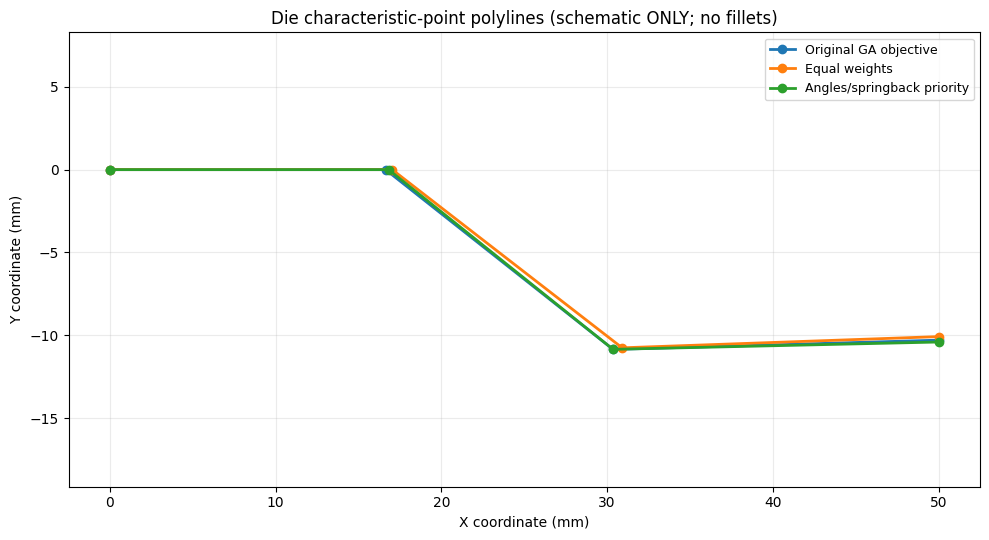

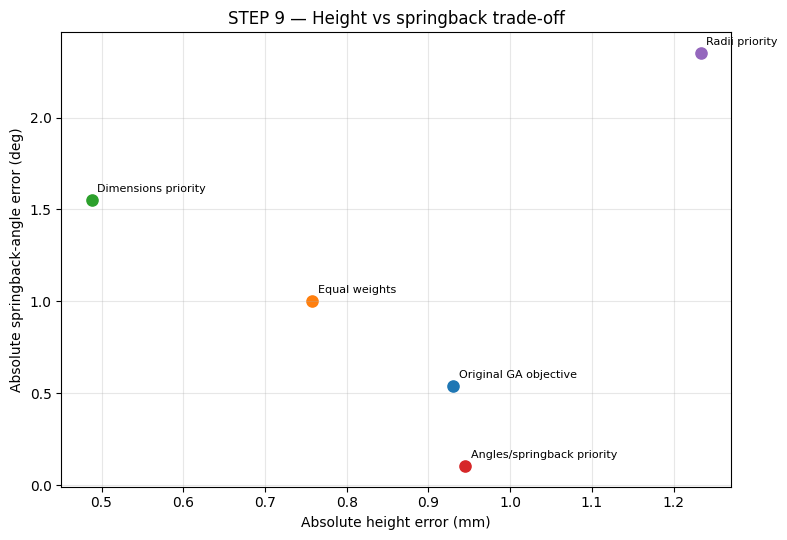


====== STEP 9 금형 입력 치수 (5개 시나리오) ======
                  scenario  die_L1 (mm)  die_L2 (mm)  die_H (mm)  die_theta1 (deg)  die_theta2 (deg)
                  baseline      16.6323      19.6400     10.8485          -38.3180            1.6311
                     equal      17.0303      19.0929     10.7516          -37.7683            2.0280
       dimensions_priority      17.0591      18.9772     10.5378          -37.0402            2.4643
angles_springback_priority      16.8145      19.6429     10.8432          -38.6833            1.2883
            radii_priority      15.4737      19.8266     11.2148          -37.3411            3.1166

====== STEP 9 목표 출력 대비 오차 ======
                  scenario                description  error_L1 (mm)  error_L2 (mm)  error_H (mm)  error_Theta1_out (deg)  error_Theta2_out (deg)  error_R1 (mm)  error_R2 (mm)
                  baseline      Original GA objective        -0.2534         0.6657        0.9302                 -2.3036                  0.53

In [3]:
# -*- coding: utf-8 -*-
"""STEP 9 — audited final design comparison for Hat ANN/GA homework.

Reads completed STEP 2 / STEP 7 / STEP 8 products from Google Drive.
No ANN retraining, no GA rerun, no use of untouched Test labels, no FEA.
Execute in Colab: %run /content/Hat_STEP9_Final_Design_Review.py
"""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('/content/drive/MyDrive')
RESULTS = ROOT / 'Hat_ANN_GA_results'
STEP7 = RESULTS / 'STEP7_GA_optimization'
STEP8 = RESULTS / 'STEP8_weight_sensitivity'
STEP9 = RESULTS / 'STEP9_final_design_review'
INPUT_COLS = ['L1', 'L2', 'H', 'theta1', 'theta2']
OUTPUT_COLS = ['L1', 'L2', 'H', 'Theta1_out', 'Theta2_out', 'R1', 'R2']
DESIGN_COLS = ['x2', 'x3', 'y3', 'offset']
TARGET = np.array([18.0, 14.0, 10.0, 40.0, 0.0, 5.5, 6.0], dtype=float)
BOUNDS = np.array([[12., 22.], [25., 33.], [-20., -10.], [-6., 6.]], dtype=float)
LABELS = {
    'baseline':'Original GA objective',
    'equal':'Equal weights',
    'dimensions_priority':'Dimensions priority',
    'angles_springback_priority':'Angles/springback priority',
    'radii_priority':'Radii priority',
}


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for piece in iter(lambda: f.read(1024*1024), b''):
            h.update(piece)
    return h.hexdigest()


def convert_to_ann_input(designs):
    """P1=(0,0), P2=(x2,0), P3=(x3,y3), P4=(50,y3+offset)."""
    x = np.asarray(designs, dtype=float)
    assert x.ndim == 2 and x.shape[1] == 4 and np.isfinite(x).all()
    x2, x3, y3, offset = x.T
    assert (x3 > x2).all(), '잘못된 금형 특징점 순서'
    l1, l2 = x2, 50.0 - x3
    y4 = y3 + offset
    h = -np.minimum(y3, y4)
    theta1 = np.degrees(np.arctan2(y3, x3-x2))
    theta2 = np.degrees(np.arctan2(offset, l2))
    return np.column_stack((l1, l2, h, theta1, theta2))


def check_inputs_and_load(root: Path, results: Path):
    s7 = results / 'STEP7_GA_optimization'
    s8 = results / 'STEP8_weight_sensitivity'
    summary_file = s8 / 'GA_weight_sensitivity_summary.csv'
    report_file = s8 / 'GA_weight_sensitivity_report.json'
    ga_file = s7 / 'GA_top5_candidates.csv'
    for f in (summary_file, report_file, ga_file):
        assert f.is_file(), f'기존 결과 파일이 없습니다: {f}'
    report = json.loads(report_file.read_text(encoding='utf-8'))
    assert report.get('status') == 'complete', 'STEP 8 미완료'
    expected_scenarios = list(LABELS)
    assert set(report['scenarios']) == set(expected_scenarios)
    expected_sources = {
        'input_csv': root/'input.csv',
        'target_csv': root/'target.csv',
        'split_indices': results/'split_indices.npz',
        'x_scaler': results/'X_scaler.joblib',
        'y_scaler': results/'Y_scaler.joblib',
        'selected_ann': results/'STEP5_hyperparameter_search'/'E_large_relu.keras',
    }
    for key, filename in expected_sources.items():
        assert filename.is_file(), f'원본 파일 누락: {filename}'
        actual = sha256_file(filename)
        assert report['sources'].get(key) == actual, f'STEP 8 이후 {key} 파일이 변경됨'
    df = pd.read_csv(summary_file)
    assert len(df) == 5 and df['scenario'].is_unique
    assert set(df['scenario']) == set(expected_scenarios)
    df = df.set_index('scenario').loc[expected_scenarios].reset_index()
    all_columns = (
        ['scenario','scenario_J_raw','common_original_weight_J',
         'common_equal_standardized_MSE','input_extrapolation_penalty',
         'nearest_train_design_distance_normalized']
        + [f'design_{c}' for c in DESIGN_COLS]
        + [f'die_{c}' for c in INPUT_COLS]
        + [f'pred_{c}' for c in OUTPUT_COLS]
        + [f'error_{c}' for c in OUTPUT_COLS]
    )
    assert set(all_columns).issubset(df.columns), 'STEP 8 결과 열 누락'
    assert np.isfinite(df.select_dtypes(include='number').to_numpy()).all()

    # 1. Physical coordinate box and geometry reconstruction.
    designs = df[[f'design_{c}' for c in DESIGN_COLS]].to_numpy(dtype=float)
    assert ((designs >= BOUNDS[:,0]-1e-7) & (designs <= BOUNDS[:,1]+1e-7)).all(), '금형 범위 이탈'
    reconstructed = convert_to_ann_input(designs)
    observed_die = df[[f'die_{c}' for c in INPUT_COLS]].to_numpy(dtype=float)
    np.testing.assert_allclose(reconstructed, observed_die, rtol=0, atol=2e-5,
                               err_msg='금형 좌표와 ANN 입력이 일치하지 않음')

    # 2. Predict/target arithmetic and shared standardized objective.
    pred = df[[f'pred_{c}' for c in OUTPUT_COLS]].to_numpy(dtype=float)
    errors = df[[f'error_{c}' for c in OUTPUT_COLS]].to_numpy(dtype=float)
    np.testing.assert_allclose(pred - TARGET[None,:], errors, rtol=0, atol=1e-5,
                               err_msg='예측값과 저장 오차 불일치')
    train_data = pd.read_csv(root/'target.csv')
    assert train_data.columns.tolist() == ['Model'] + OUTPUT_COLS
    with np.load(results/'split_indices.npz') as split:
        train_idx = split['train']
        valid_idx = split['validation']
        test_idx = split['test']
    assert [len(train_idx),len(valid_idx),len(test_idx)] == [623,134,134]
    np.testing.assert_array_equal(np.sort(np.r_[train_idx,valid_idx,test_idx]),np.arange(891))
    std = train_data.iloc[train_idx][OUTPUT_COLS].to_numpy(dtype=float).std(axis=0, ddof=0)
    assert (std>1e-10).all()
    z = errors / std[None,:]
    calc_common = np.mean(z*z,axis=1)
    np.testing.assert_allclose(calc_common,df['common_equal_standardized_MSE'],
                               atol=1e-5,rtol=1e-5,err_msg='공통 MSE 재계산 불일치')
    penalty = df['input_extrapolation_penalty'].to_numpy(dtype=float)
    assert (penalty>=-1e-7).all(), '음수 설계 범위 페널티'
    base_w = np.asarray(report['scenarios']['baseline'],dtype=float)
    calc_base = (base_w[None,:]*z*z).sum(axis=1)+penalty
    np.testing.assert_allclose(calc_base,df['common_original_weight_J'],
                               atol=1e-5,rtol=1e-5,err_msg='기존 목적함수 재계산 불일치')
    calc_scenario = np.array([
        (np.asarray(report['scenarios'][name],dtype=float)*z[i]*z[i]).sum()+penalty[i]
        for i,name in enumerate(df['scenario'])
    ])
    np.testing.assert_allclose(calc_scenario, df['scenario_J_raw'],
                               atol=1e-5,rtol=1e-5,err_msg='시나리오 목적함수 재계산 불일치')
    # 3. Baseline must be exactly STEP 7's rank-1 candidate (CSV precision tolerance).
    base_row = df[df['scenario']=='baseline'].iloc[0]
    ga_top = pd.read_csv(ga_file)
    assert len(ga_top)>=1 and ga_top.iloc[0]['rank']==1
    np.testing.assert_allclose(
        base_row[[f'design_{c}' for c in DESIGN_COLS]].to_numpy(dtype=float),
        ga_top.iloc[0][DESIGN_COLS].to_numpy(dtype=float),atol=2e-4,rtol=0,
        err_msg='STEP 7 최우수해와 STEP 8 Baseline 후보가 다름'
    )
    np.testing.assert_allclose(base_row['common_original_weight_J'],ga_top.iloc[0]['J'],
                               atol=2e-4,rtol=0)
    return df, report, std, z


def build_tables(df: pd.DataFrame):
    identity = pd.DataFrame({'scenario':df['scenario'], 'description':df['scenario'].map(LABELS)})
    design = identity.copy()
    for name in DESIGN_COLS:
        design[name+' (mm)'] = df[f'design_{name}']
    for col in INPUT_COLS:
        unit = 'deg' if 'theta' in col else 'mm'
        design[f'die_{col} ({unit})'] = df[f'die_{col}']
    predicted = identity.copy()
    for col in OUTPUT_COLS:
        unit = 'deg' if 'Theta' in col else 'mm'
        predicted[f'{col} ({unit})'] = df[f'pred_{col}']
    errors = identity.copy()
    for col in OUTPUT_COLS:
        unit = 'deg' if 'Theta' in col else 'mm'
        errors[f'error_{col} ({unit})'] = df[f'error_{col}']
    scores = identity.copy()
    for col in ['common_original_weight_J','common_equal_standardized_MSE',
                'nearest_train_design_distance_normalized','input_extrapolation_penalty']:
        scores[col] = df[col]
    scores['abs_springback_error_deg']=df['error_Theta2_out'].abs()
    scores['abs_height_error_mm']=df['error_H'].abs()
    return design, predicted, errors, scores


def figure_error_heatmap(df,z,out):
    fig,ax=plt.subplots(figsize=(11,4.8))
    abs_z=np.abs(z)
    im=ax.imshow(abs_z,cmap='YlOrRd',aspect='auto')
    ax.set_yticks(range(len(df)),[LABELS[s] for s in df['scenario']])
    ax.set_xticks(range(7), OUTPUT_COLS,rotation=25,ha='right')
    for r in range(len(df)):
        for c in range(7):
            ax.text(c,r,f'{abs_z[r,c]:.2f}',ha='center',va='center',fontsize=9)
    fig.colorbar(im,ax=ax,label='|Predicted - target| / Train SD')
    ax.set_title('STEP 9 — Target errors on comparable standardized scale')
    fig.tight_layout()
    fig.savefig(out/'STEP9_error_heatmap.png',dpi=190,bbox_inches='tight')
    plt.show();plt.close(fig)


def figure_profiles(df,out):
    chosen=['baseline','equal','angles_springback_priority']
    fig,ax=plt.subplots(figsize=(10,5.5))
    for scenario in chosen:
        r=df.loc[df['scenario']==scenario].iloc[0]
        x2,x3,y3,off=[float(r[f'design_{c}']) for c in DESIGN_COLS]
        xs=[0,x2,x3,50];ys=[0,0,y3,y3+off]
        ax.plot(xs,ys,marker='o',label=LABELS[scenario],linewidth=2)
    ax.set_aspect('equal',adjustable='datalim')
    ax.set(xlabel='X coordinate (mm)',ylabel='Y coordinate (mm)',
           title='Die characteristic-point polylines (schematic ONLY; no fillets)')
    ax.grid(alpha=.25);ax.legend(loc='best',fontsize=9)
    fig.tight_layout()
    fig.savefig(out/'STEP9_die_profiles_schematic.png',dpi=190,bbox_inches='tight')
    plt.show();plt.close(fig)


def figure_tradeoff(df,out):
    fig,ax=plt.subplots(figsize=(8,5.5))
    for _,r in df.iterrows():
        x=abs(float(r['error_H'])); y=abs(float(r['error_Theta2_out']))
        ax.scatter([x],[y],s=65)
        ax.annotate(LABELS[r['scenario']],(x,y),xytext=(4,6),
                    textcoords='offset points',fontsize=8)
    ax.set(xlabel='Absolute height error (mm)',ylabel='Absolute springback-angle error (deg)',
           title='STEP 9 — Height vs springback trade-off')
    ax.grid(alpha=.3);fig.tight_layout()
    fig.savefig(out/'STEP9_height_springback_tradeoff.png',dpi=190,bbox_inches='tight')
    plt.show();plt.close(fig)


def main():
    from google.colab import drive
    drive.mount('/content/drive')
    print('STEP 9: 기존 결과 검증 시작',flush=True)
    df, report, std, z=check_inputs_and_load(ROOT,RESULTS)
    print('STEP 2·7·8 원본 해시 / 설계변수 / 목적함수 교차검증: PASS',flush=True)
    out = STEP9
    out.mkdir(parents=True,exist_ok=True)
    design,predicted,errors,scores=build_tables(df)
    for name,frame in [
        ('STEP9_all_designs.csv',design),
        ('STEP9_all_predictions.csv',predicted),
        ('STEP9_all_signed_errors.csv',errors),
        ('STEP9_common_metrics.csv',scores),
    ]:
        frame.to_csv(out/name,index=False,float_format='%.10f')

    # Pre-defined reporting choices, not model retraining or a data-driven retuning of ANN.
    baseline=df.loc[df.scenario=='baseline'].iloc[0]
    equal=df.loc[df.scenario=='equal'].iloc[0]
    angle=df.loc[df.scenario=='angles_springback_priority'].iloc[0]
    assert df.loc[df.common_original_weight_J.idxmin(),'scenario']=='baseline', '원래 목적함수 최적 후보가 변함'
    assert df.loc[df.common_equal_standardized_MSE.idxmin(),'scenario']=='equal', '균등 가중치 결과 확인 필요'
    assert df.loc[df.error_Theta2_out.abs().idxmin(),'scenario']=='angles_springback_priority', '스프링백 최소 후보 확인 필요'
    comparison = []
    for col in OUTPUT_COLS:
        unit='deg' if 'Theta' in col else 'mm'
        t=float(TARGET[OUTPUT_COLS.index(col)])
        comparison.append({'variable':col,'unit':unit,'target':t,
                           'baseline_prediction':float(baseline['pred_'+col]),
                           'baseline_error':float(baseline['error_'+col]),
                           'angle_priority_prediction':float(angle['pred_'+col]),
                           'angle_priority_error':float(angle['error_'+col]),
                           'equal_prediction':float(equal['pred_'+col]),
                           'equal_error':float(equal['error_'+col])})
    comparison=pd.DataFrame(comparison)
    comparison.to_csv(out/'STEP9_baseline_angle_equal_comparison.csv',index=False,float_format='%.10f')

    figure_error_heatmap(df,z,out)
    figure_profiles(df,out)
    figure_tradeoff(df,out)

    improvement=100*(1-abs(float(angle['error_Theta2_out']))/abs(float(baseline['error_Theta2_out'])))
    relative_j=100*(float(angle['common_original_weight_J'])/float(baseline['common_original_weight_J'])-1)
    audit={
        'status':'complete',
        'source_step8_sha256':sha256_file(STEP8/'GA_weight_sensitivity_summary.csv'),
        'source_step8_report_sha256':sha256_file(STEP8/'GA_weight_sensitivity_report.json'),
        'original_objective_best':'baseline',
        'equal_weight_common_MSE_best':'equal',
        'lowest_abs_springback_error':'angles_springback_priority',
        'baseline_original_J':float(baseline['common_original_weight_J']),
        'angle_priority_original_J':float(angle['common_original_weight_J']),
        'angle_priority_relative_original_J_increase_percent':float(relative_j),
        'angle_priority_springback_error_reduction_percent':float(improvement),
        'target_order':OUTPUT_COLS,
        'target':TARGET.tolist(),
        'train_output_std_ddof0':std.tolist(),
        'limitations':[
            'Predictions are from frozen ANN surrogate; no new ABAQUS or physical validation.',
            'R1/R2 prediction uncertainty is materially higher than most other outputs.',
            'Die profile drawing connects 4 feature points; it omits R1/R2 fillets and clearance.',
            'Comparing scenario-specific J directly is invalid; compare common metrics or original-J.',
            'Input-domain penalty is soft and does not prove manufacturing feasibility.',
        ],
    }
    (out/'STEP9_selection_audit.json').write_text(
        json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8')
    notes = f'''# STEP 9 — 최적 금형 설계 결과 정리\n\n'''
    notes += ('- 최초 목적함수 기준 최적해: **baseline** '
              f'(J={audit["baseline_original_J"]:.6f}).\n')
    notes += ('- 전체 변수 공통 정규화 MSE 최소: **equal** '
              f'(MSE={float(equal["common_equal_standardized_MSE"]):.6f}).\n')
    notes += ('- 스프링백 절대오차 최소: **angles_springback_priority** '
              f'(|θspb 오차|={abs(float(angle["error_Theta2_out"])):.4f}°).\n')
    notes += (f'- 스프링백 우선 후보는 baseline 대비 각도 오차 {improvement:.1f}% 감소, '
              f'원래 목적함수 J는 {relative_j:.2f}% 증가.\n\n')
    notes += ('## 보고서 해석 원칙\n\n'
              '원래 목적함수 최적해를 기준 설계로 유지하고, 스프링백 우선 해를 비교 개선안으로 보고한다. '
              '새로운 가중치별 J 자체를 서로 직접 비교하지 않는다. '
              '아래 표·그래프는 ANN 예측이며 실제 ABAQUS 성형 검증이 아니다. '
              '금형 외곽 필렛 및 펀치·다이 간섭, 실제 제조 가능성은 검증하지 않았다.\n')
    (out/'STEP9_PPT_ready_notes.md').write_text(notes,encoding='utf-8')

    print('\n====== STEP 9 금형 입력 치수 (5개 시나리오) ======',flush=True)
    view=['scenario']+[f'die_{c} ({"deg" if "theta" in c else "mm"})' for c in INPUT_COLS]
    print(design[view].round(4).to_string(index=False),flush=True)
    print('\n====== STEP 9 목표 출력 대비 오차 ======',flush=True)
    print(errors.round(4).to_string(index=False),flush=True)
    print('\n====== 추천 비교: Baseline vs 각도·스프링백 우선 vs Equal ======',flush=True)
    print(comparison.round(4).to_string(index=False),flush=True)
    print(f'\n스프링백 우선 후보: 각도 절대오차 {improvement:.1f}% 감소; '
          f'원래 J {relative_j:+.2f}% 변화',flush=True)
    print('출력 저장 폴더:',out,flush=True)
    print('STEP 9: PASS (수치·파일 일관성 검증; FEA/제작 검증 별도)',flush=True)


if __name__ == '__main__':
    main()


## STEP 10 — 새로 추가된 독립 점검 셀

아래 코드는 기존 신경망·GA를 다시 돌리지 않고, **CSV 891건/변수 정의/Train-only 정규화/파일 해시/목표 출력 7개/설계좌표의 역변환/간단한 2D 필렛 접선 길이 여유**를 확인한다.

**주의:** 현재 저장된 STEP 1–9의 실행 결과는 검토 대상 자료다. 이 STEP 10 코드의 실행 결과는 이 파일 제작 시점에 Colab의 실제 Google Drive에서 새로 수행하지 않았으므로 **실행 전 PASS라고 주장하지 않는다.** 스크립트를 실행하여 표시되는 PASS를 확인해야 한다. 필렛의 단순 접선 길이 검사도 실제 금형 간섭이나 FEA 타당성을 보증하지 않는다.

In [ ]:
# -*- coding: utf-8 -*-
"""STEP 10 — 교수 자료/코드/산출물 최종 검증 (예측 재실행·재학습 없음).

실행 환경: Google Colab, STEP 1~9 산출물이 MyDrive에 저장된 상태.
통과는 데이터·수식·저장값의 일관성을 뜻하며, Abaqus FEA/실험 검증이 아님.
"""
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import joblib

ROOT = Path('/content/drive/MyDrive')
RESULTS = ROOT / 'Hat_ANN_GA_results'
OUT = RESULTS / 'STEP10_final_audit'
INPUT_COLS = ['L1','L2','H','theta1','theta2']
OUTPUT_COLS = ['L1','L2','H','Theta1_out','Theta2_out','R1','R2']
DESIGN_COLS = ['x2','x3','y3','offset']
TARGET = np.array([18.,14.,10.,40.,0.,5.5,6.], dtype=float)
BOUNDS = np.array([[12.,22.],[25.,33.],[-20.,-10.],[-6.,6.]])
BASE_W = np.array([1.,1.,2.,3.,4.,3.,3.])


def sha256(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()


def to_inputs(designs):
    d = np.asarray(designs, dtype=float)
    assert d.ndim == 2 and d.shape[1] == 4
    a,b,c,o = d.T
    assert (b>a).all()
    l2 = 50.-b
    h = -np.minimum(c,c+o)
    return np.column_stack([
        a,l2,h,
        np.rad2deg(np.arctan2(c,b-a)),
        np.rad2deg(np.arctan2(o,l2))
    ])


def to_designs(x):
    x = np.asarray(x,dtype=float)
    a,l2,h,t1,t2 = x.T
    b = 50.-l2
    c = (b-a)*np.tan(np.deg2rad(t1))
    o = l2*np.tan(np.deg2rad(t2))
    return np.column_stack([a,b,c,o])


def fillet_tangent_margins(designs, r1=5., r2=6.):
    """단순 2D 직선-원호 접선 길이 여유; 실제 CAD/펀치 간섭·FEA 검증 아님."""
    d = np.asarray(designs, dtype=float)
    x2,x3,y3,off = d.T
    a1=np.arctan2(y3,x3-x2)
    a2=np.arctan2(off,50-x3)
    t1=r1*np.tan(np.abs(a1)/2)
    t2=r2*np.tan(np.abs(a2-a1)/2)
    return np.column_stack([
        x2-t1,
        np.hypot(x3-x2,y3)-t1-t2,
        np.hypot(50-x3,off)-t2
    ])


def run_audit():
    from google.colab import drive
    drive.mount('/content/drive')
    paths = {
        'input_csv': ROOT/'input.csv',
        'target_csv': ROOT/'target.csv',
        'split_indices': RESULTS/'split_indices.npz',
        'x_scaler': RESULTS/'X_scaler.joblib',
        'y_scaler': RESULTS/'Y_scaler.joblib',
    }
    model_meta=RESULTS/'STEP5_hyperparameter_search'/'selected_model_info.json'
    step6_meta=RESULTS/'STEP6_independent_test'/'test_evaluation_info.json'
    step7_meta=RESULTS/'STEP7_GA_optimization'/'GA_result_info.json'
    step8_meta=RESULTS/'STEP8_weight_sensitivity'/'GA_weight_sensitivity_report.json'
    step9_meta=RESULTS/'STEP9_final_design_review'/'STEP9_selection_audit.json'
    summary_csv=RESULTS/'STEP8_weight_sensitivity'/'GA_weight_sensitivity_summary.csv'
    for p in [*paths.values(),model_meta,step6_meta,step7_meta,step8_meta,step9_meta,summary_csv]:
        assert p.is_file(), f'필수 파일 누락: {p}'

    xin=pd.read_csv(paths['input_csv'])
    yout=pd.read_csv(paths['target_csv'])
    assert xin.shape==yout.shape==(891,8)
    assert xin.columns.tolist()==['Model',*INPUT_COLS,'R1','R2']
    assert yout.columns.tolist()==['Model',*OUTPUT_COLS]
    assert xin['Model'].equals(yout['Model']) and xin['Model'].is_unique
    assert np.isfinite(xin.select_dtypes(include='number').to_numpy()).all()
    assert np.isfinite(yout.select_dtypes(include='number').to_numpy()).all()
    assert (xin['R1']==5).all() and (xin['R2']==6).all()
    observed = set(xin['Model'].astype(int))
    assert min(observed)>=1 and max(observed)<=900
    missing = sorted(set(range(1,901))-observed)
    assert len(missing)==9, f'예상 누락 ID 9개와 불일치: {missing}'

    design = to_designs(xin[INPUT_COLS].to_numpy())
    back = to_inputs(design)
    max_geom_err=float(np.max(np.abs(back-xin[INPUT_COLS].to_numpy())))
    assert max_geom_err < 1e-5
    assert np.all(design >= BOUNDS[:,0]-1e-5)
    assert np.all(design <= BOUNDS[:,1]+1e-5)
    margins_data=fillet_tangent_margins(design)
    assert np.all(margins_data>0), '원본 형상의 단순 필렛 접선 길이 검사 실패'

    with np.load(paths['split_indices']) as z:
        tr,va,te=(z['train'],z['validation'],z['test'])
    assert [len(tr),len(va),len(te)]==[623,134,134]
    np.testing.assert_array_equal(np.sort(np.r_[tr,va,te]),np.arange(891))
    sx=joblib.load(paths['x_scaler'])
    sy=joblib.load(paths['y_scaler'])
    np.testing.assert_allclose(sx.data_min_,xin.iloc[tr][INPUT_COLS].min().to_numpy())
    np.testing.assert_allclose(sx.data_max_,xin.iloc[tr][INPUT_COLS].max().to_numpy())
    np.testing.assert_allclose(sy.data_min_,yout.iloc[tr][OUTPUT_COLS].min().to_numpy())
    np.testing.assert_allclose(sy.data_max_,yout.iloc[tr][OUTPUT_COLS].max().to_numpy())
    std=yout.iloc[tr][OUTPUT_COLS].to_numpy(dtype=float).std(axis=0,ddof=0)
    assert np.all(std>1e-8)

    s5=json.loads(model_meta.read_text(encoding='utf-8'))
    assert s5['input_columns']==INPUT_COLS and s5['output_columns']==OUTPUT_COLS
    selected_model=Path(s5['model_path'])
    assert selected_model.is_file()
    paths['selected_ann']=selected_model
    hashes={name:sha256(path) for name,path in paths.items()}
    s6=json.loads(step6_meta.read_text(encoding='utf-8'))
    s7=json.loads(step7_meta.read_text(encoding='utf-8'))
    s8=json.loads(step8_meta.read_text(encoding='utf-8'))
    s9=json.loads(step9_meta.read_text(encoding='utf-8'))
    assert s6['source_hashes']==hashes and s7['sources']==hashes and s8['sources']==hashes
    assert s7['status']=='complete' and s8['status']=='complete' and s9['status']=='complete'
    assert np.allclose(s7['config']['weights'],BASE_W)
    assert np.allclose(s7['config']['target'],TARGET)

    summary=pd.read_csv(summary_csv)
    assert summary.shape[0]==5 and summary['scenario'].is_unique
    assert set(summary['scenario'])=={'baseline','equal','dimensions_priority','angles_springback_priority','radii_priority'}
    design5=summary[[f'design_{v}' for v in DESIGN_COLS]].to_numpy(dtype=float)
    np.testing.assert_allclose(to_inputs(design5),summary[[f'die_{v}' for v in INPUT_COLS]].to_numpy(),atol=2e-5,rtol=0)
    margins_opt=fillet_tangent_margins(design5)
    assert np.all(margins_opt>0), 'GA 후보의 단순 필렛 접선 길이 검사 실패'
    prediction=summary[[f'pred_{v}' for v in OUTPUT_COLS]].to_numpy(dtype=float)
    residual=(prediction-TARGET[None,:])
    np.testing.assert_allclose(residual,summary[[f'error_{v}' for v in OUTPUT_COLS]].to_numpy(),atol=1e-5,rtol=0)
    common_mse=np.mean((residual/std[None,:])**2,axis=1)
    np.testing.assert_allclose(common_mse,summary['common_equal_standardized_MSE'],atol=1e-5,rtol=1e-5)
    penalty=summary['input_extrapolation_penalty'].to_numpy()
    basej=np.sum(BASE_W[None,:]*(residual/std[None,:])**2,axis=1)+penalty
    np.testing.assert_allclose(basej,summary['common_original_weight_J'],atol=1e-5,rtol=1e-5)
    assert summary.loc[summary['common_original_weight_J'].idxmin(),'scenario']=='baseline'

    out={
        'status':'numerical_consistency_pass',
        'data_rows':891,'missing_model_ids':missing,
        'input_features':INPUT_COLS,'output_features':OUTPUT_COLS,
        'target_in_output_order':TARGET.tolist(),
        'max_original_geometry_reconstruction_error':max_geom_err,
        'min_training_geometry_fillet_tangent_margin_mm':float(margins_data.min()),
        'min_5_optima_fillet_tangent_margin_mm':float(margins_opt.min()),
        'train_validation_test_sizes':[len(tr),len(va),len(te)],
        'final_selected_ann':s5['winner'],
        'min_original_objective_J':float(basej.min()),
        'important_limitations':[
            '독립 Test 점수로 재학습하거나 GA를 재선정하지 않음',
            'R1/R2 출력의 일반화 성능은 길이/각도보다 낮음',
            '가중치 수치는 논문의 정해진 숫자가 아니라 본 과제의 선택',
            '필렛 접선 여유는 단순 2D 검토이며 CAD 접촉/제작 검증이 아님',
            '실제 Abaqus FEA 재해석·실험 미실시',
            'ANN 예측과 목표의 잔차가 0은 아님',
        ],
    }
    OUT.mkdir(parents=True,exist_ok=True)
    (OUT/'STEP10_numeric_audit.json').write_text(json.dumps(out,indent=2,ensure_ascii=False),encoding='utf-8')
    print('STEP 10 숫자·기하학·출처·산출물 일관성 검사: PASS')
    print('누락 Model 번호:',missing)
    print('원본 복원 최대오차:',max_geom_err)
    print('2D 단순 필렛 접선 최소여유 (데이터/최적 후보):',round(out['min_training_geometry_fillet_tangent_margin_mm'],4),round(out['min_5_optima_fillet_tangent_margin_mm'],4),'mm')
    print('원래 목적함수 최소:',round(out['min_original_objective_J'],6))
    print('주의: Abaqus/제작/전 형상 간섭 검증 PASS 아님')
    return out

if __name__ == '__main__':
    run_audit()
